# Búsqueda en Inteligencia Artificial

### Unidad 3, Razonamiento en ambientes deterministas

## Material de lectura

Se debe leer:

* Libro:
  * Sección 3.1
  * <font color='gray'>Sección 3.2 (sugerido) </font>
  * Sección 3.3
  * Sección 3.4 hasta "Búsqueda de profundidad limitada" incluida. Ver también el cuadro de la figura 3.17.
  * Sección 3.5
  * Sección 4.1 hasta "Búsqueda A*" incluida.
  * Sección 4.2
* Material complementario

## Tipo de problema

* Es el ambiente más simple donde se puede desempeñar un agente inteligente:
  * Totalmente observable
  * Determinista
  * Episódico
  * Estático
  * Discreto
  * Agente individual
  * Conocido

* Consideraremos un **estado objetivo** como un conjunto de estados del mundo (exactamente aquellos estados que satisfacen el objetivo).

* La tarea del agente es encontrar una secuencia de acciones permita obtener un estado objetivo.

* Existe un subconjunto de problemas donde los problemas se pueden definir mediante:
  * Un estado objetivo
  * Un estado inicial
  * Un conjunto de acciones posibles
  * Una función de costo del camino

Sobre este tipo de problemas se pueden aplicar las técnicas de búsqueda.


## Sistemas de producción

Debido a que la búsqueda es el núcleo de muchos procesos inteligentes, es útil estructurar los programas de IA de forma que se facilite describir y desarrollar el proceso de bśqueda. Los sistemas de producción proporcionan estas estructuras. Están formados por:
* Un conjunto de reglas tipo ```condición → acción```
* Una base de conocimiento
* Una estrategia de control
* Un aplicador de reglas

Desde el punto de vista de nuestra materia, IAR, el uso de los sistemas de producción se extiende a casi todos las técnicas de IA, dado que la mayoría de los problemas se pueden ver como un proceso de búsqueda en un espacio de estados (aunque no necesariamente con las técnicas que vemos en este notebook). Lo veremos en el resto de las clases.

## Ejemplo de problema

<center>

**8-puzzle**

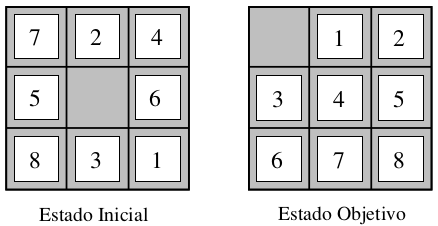

## Definición del problema

Para resolver un problema de búsqueda es necesario:

* La definición formal del problema
  * Estado objetivo
  * Estado inicial
  * Conjunto de acciones posibles
  * Función de costo del camino

* Una estrategia de búsqueda

Para implementar la búsqueda es necesario encontrar o crear:
* Una forma de representar el los estados inicial, final e intermedios.
* Un conjunto de reglas compuestas por una condición de aplicación y una operación.
* Una estrategia de control para decidir el orden de aplicación de las reglas.


## Definiciones y representaciones para el problema del ejemplo

* Ejemplo de reglas para 8-puzzle:

  * Si el espacio vacío no está en la última línea, subir la ficha que está abajo del espacio vacío.
  * Si el espacio vacío no está en la primera línea, bajar la ficha que está arriba del espacio vacío.
  * Si el espacio vacío no está en la última columna, mover hacia la izquierda la ficha que está a la derecha del espacio vacío.
  * Si el espacio vacío no está en la primera columna, mover hacia la derecha la ficha que está a la izquierda del espacio vacío.

* La representación de los estados es fácil, una matriz de tamaño $3 \times 3$ conteniendo los caracteres " ", "1", "2", "3", "4", "5", "6", "7" y "8".
* Podemos definir el costo de cada movimiento $= 1$.


## Espacio de estados

De la definición formal del problema surge el concepto de espacio de estados o espacio de búsqueda, que se define como el **conjunto de todos los estados que pueden ser alcanzados aplicando acciones a partir del estado inicial**.

Es importante entender que el espacio de estados existe solo como una posibilidad, no está disponible ni se lo conoce.


<center>

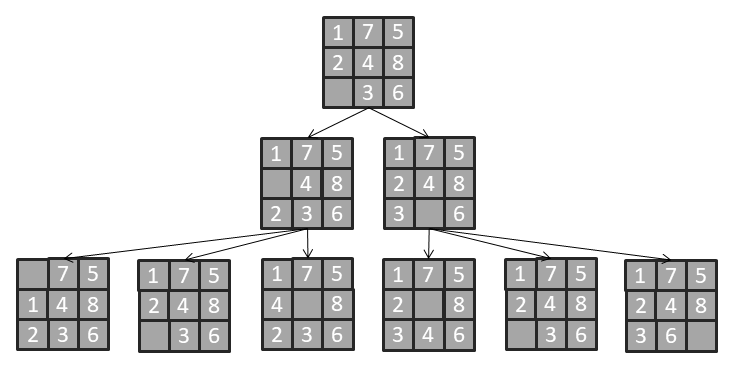

Un camino en el espacio de estados es una secuencia de estados conectados por acciones

## Salida de un método de búsqueda


Generalmente, la salida esperada de un método de búsqueda es el camino entre el estado inicial y el estado objetivo (camino de la solución).

En algunos casos el estado mismo objetivo es la salida esperada (cinemática inversa, 8 reinas)


## Camino solución vs camino de búsqueda

* El camino de la solución es la sucesión de estados, que comienza con el estado inicial y termina con el estado objetivo, donde cada estado puede ser generado aplicando una operación sobre el estado anterior. Es el camino “encontrado” por el método como solución al problema.

* El camino de búsqueda es la sucesión de estados explorados por el método hasta encontrar la solución. No están conectados por acciones.


## Calidad de la solución




* La calidad de una solución se mide por la función de costo del camino
* La solución óptima es la que tiene el costo más bajo

## Rendimiento del método

* Completitud (Si la solución existe, ¿El método garantiza encontrarla?)
* Optimalidad (¿El método garantiza encontrar la solución óptima?)
* Complejidad temporal
* Complejidad espacial

Conceptos importantes:
* Factor de ramificación
* Profundidad del estado objetivo más cercano al estado inicial

## Estados repetidos?

<center>

**Árboles vs Grafos**

Aclaración: No hacemos una búsqueda en un grafo, lo creamos "involuntariamente" mientras buscamos.

## Tipos de métodos

* No informados
  * Primero en amplitud (FIFO)
  * Primero en profundidad (LIFO)
* Informados (heurísticos)
  * Primero el mejor
  * A*


## Primero en Amplitud

### Ejemplo

<center>

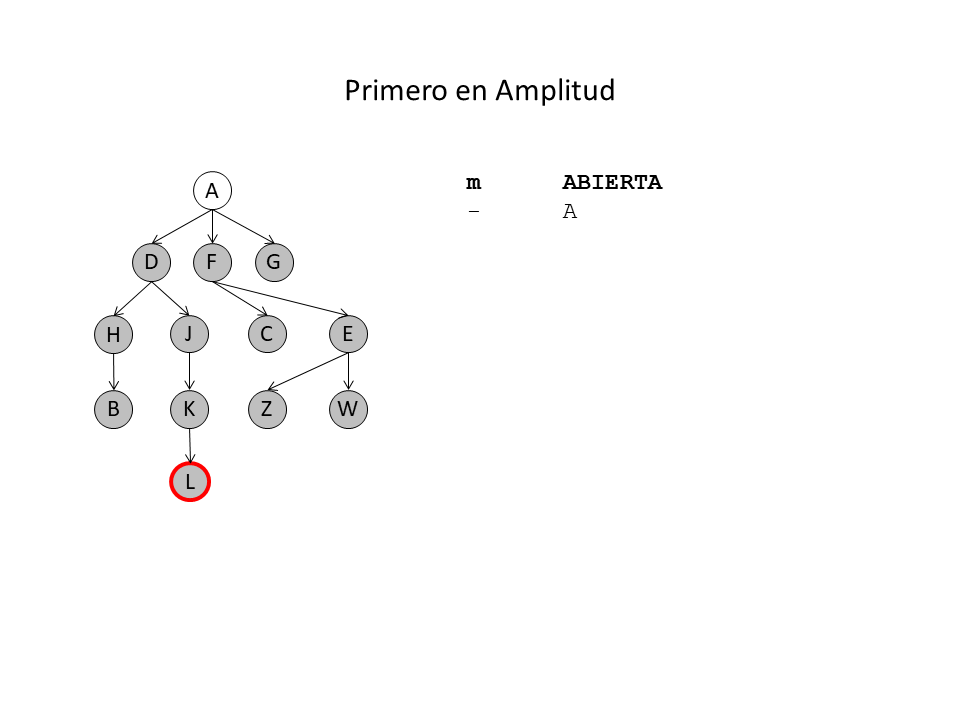

<center>

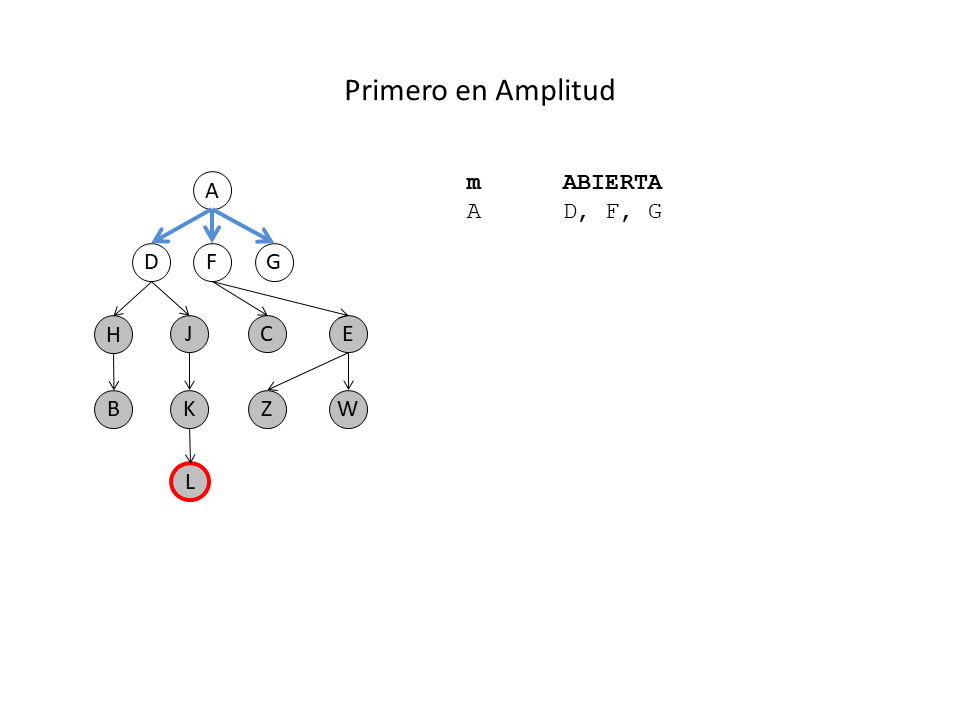

<center>

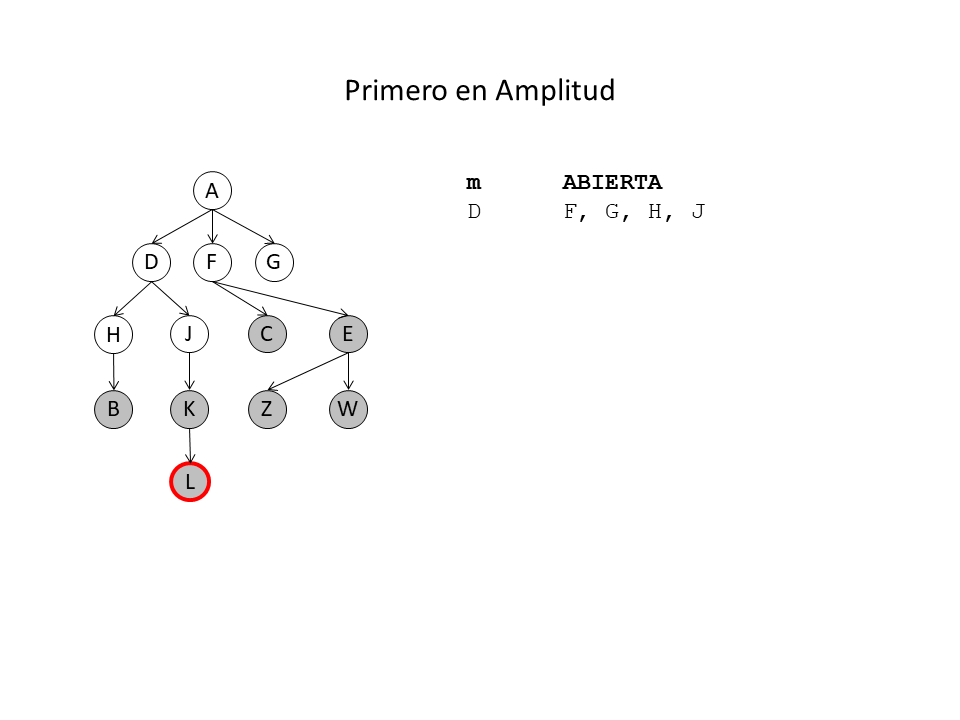

<center>

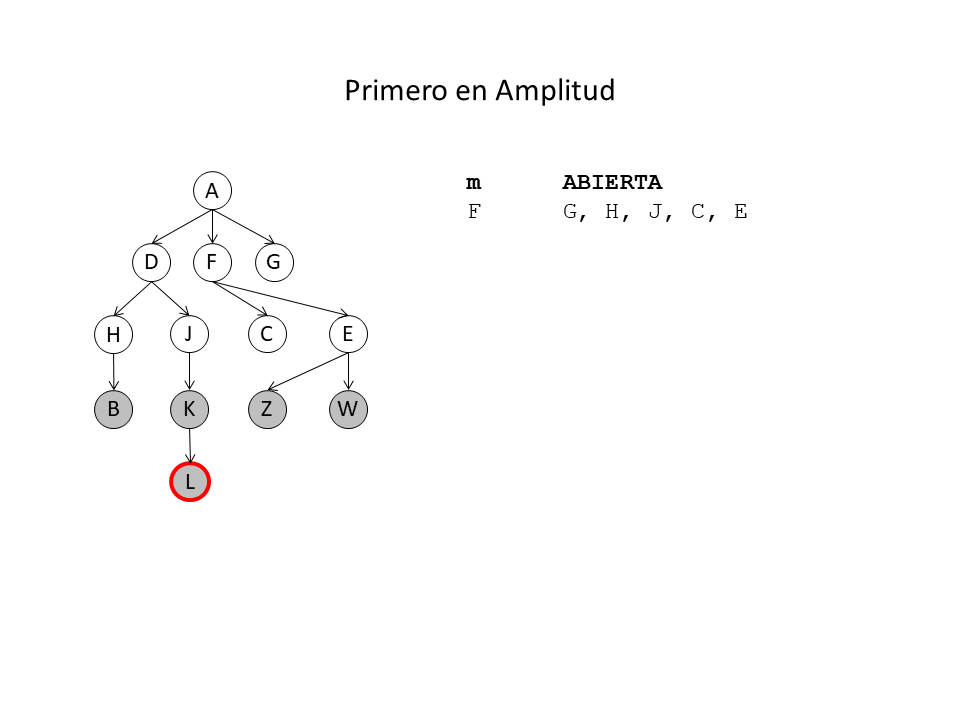

<center>

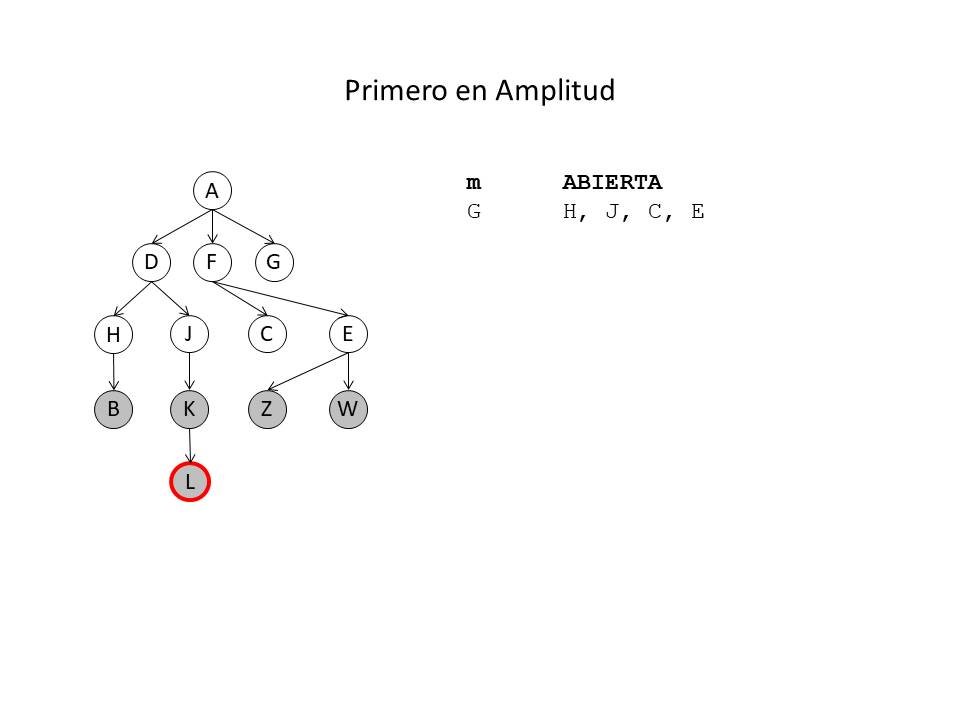

<center>

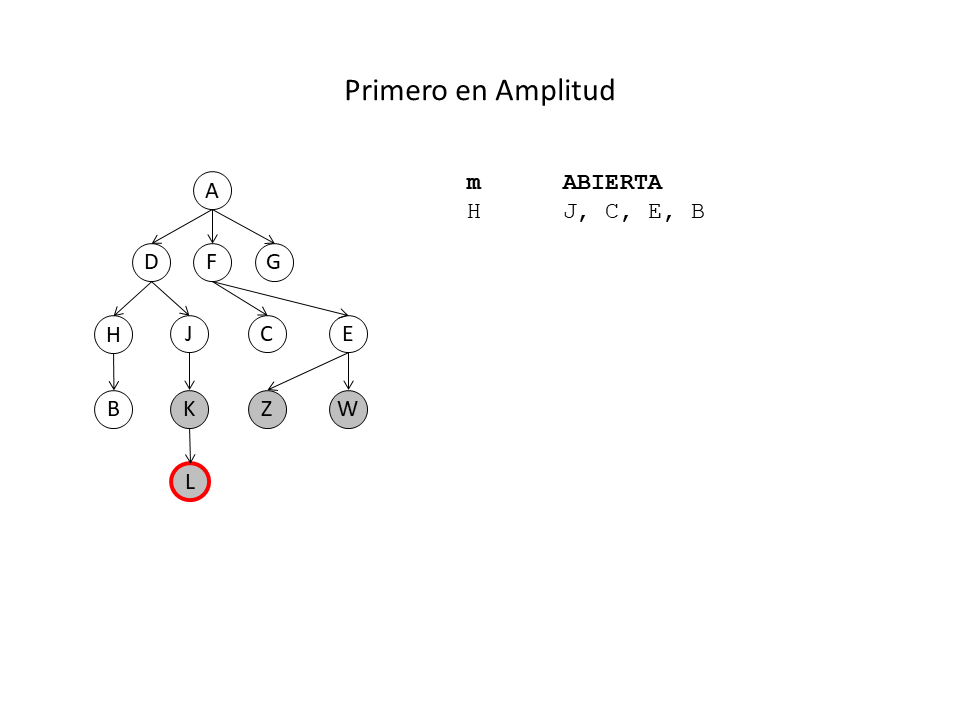

<center>

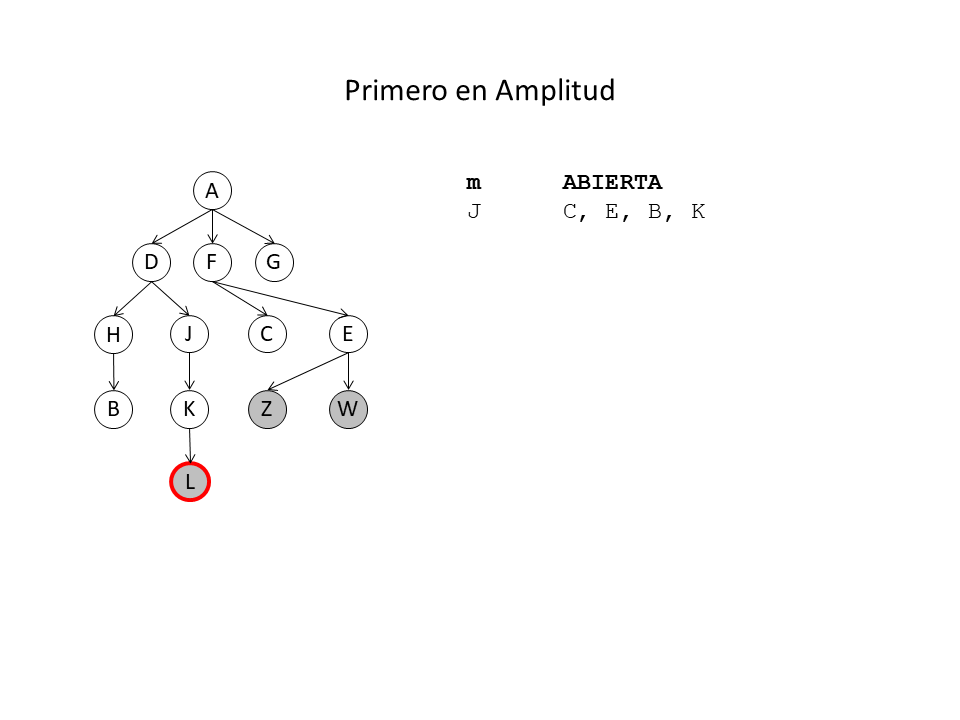

<center>

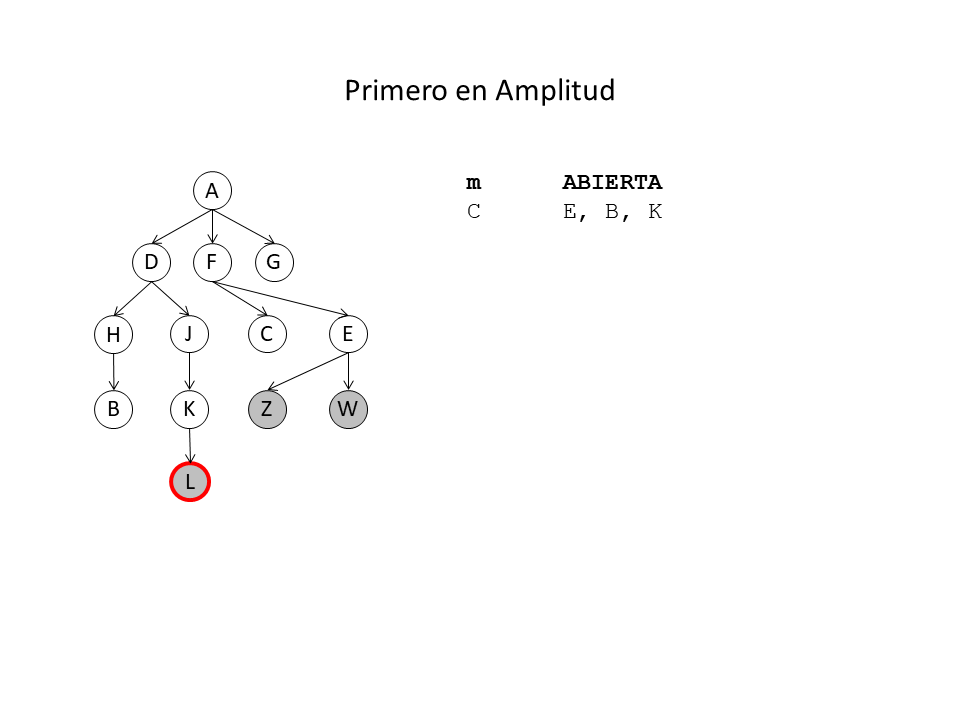

<center>

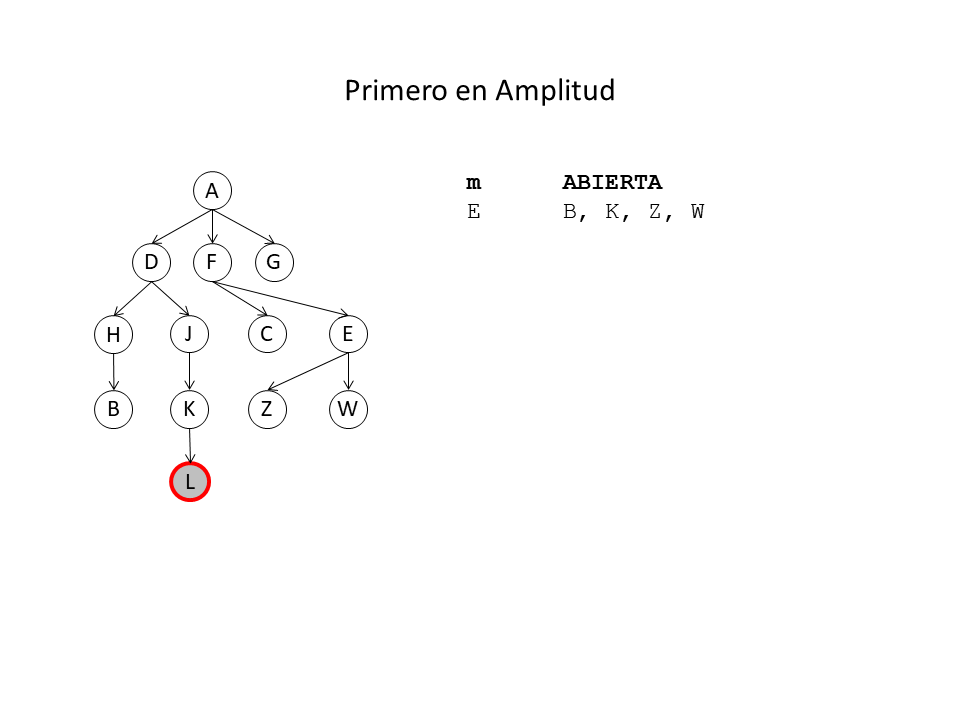

<center>

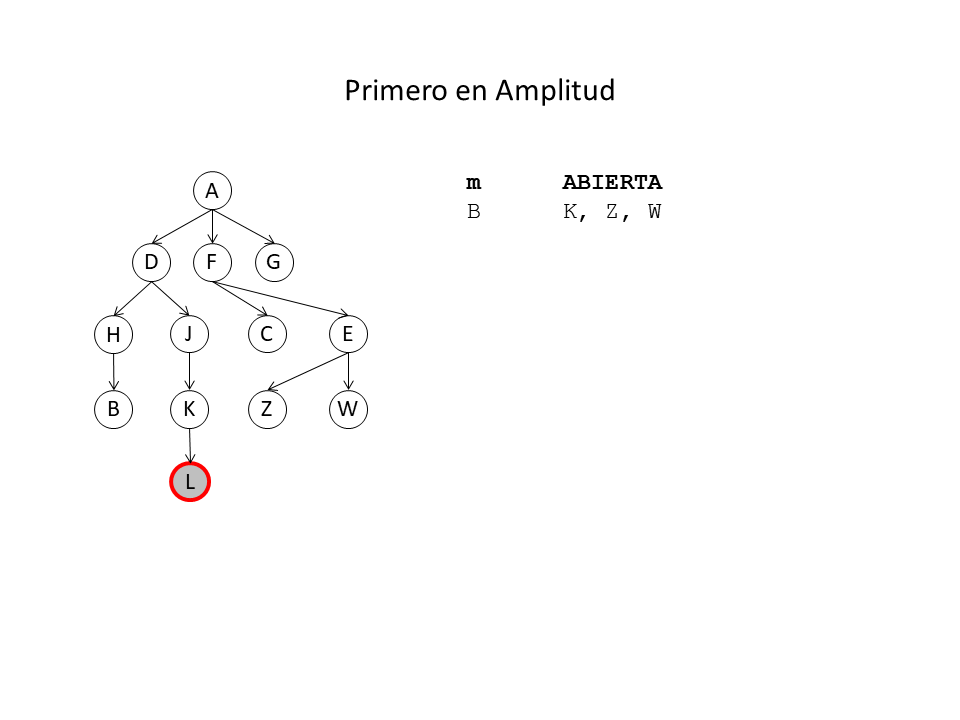

<center>

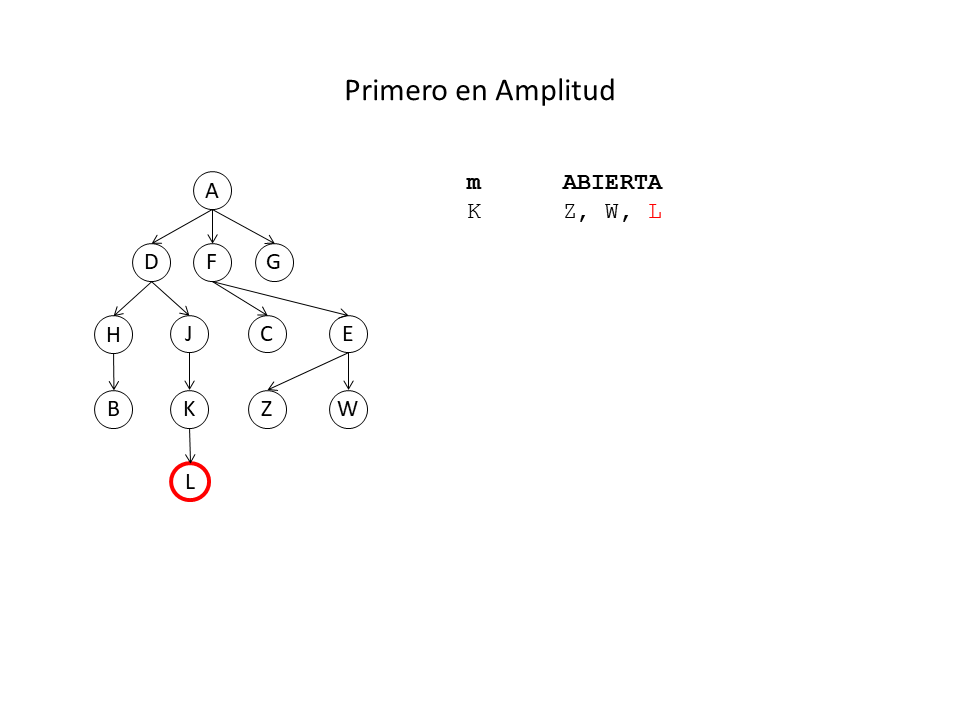

<center>

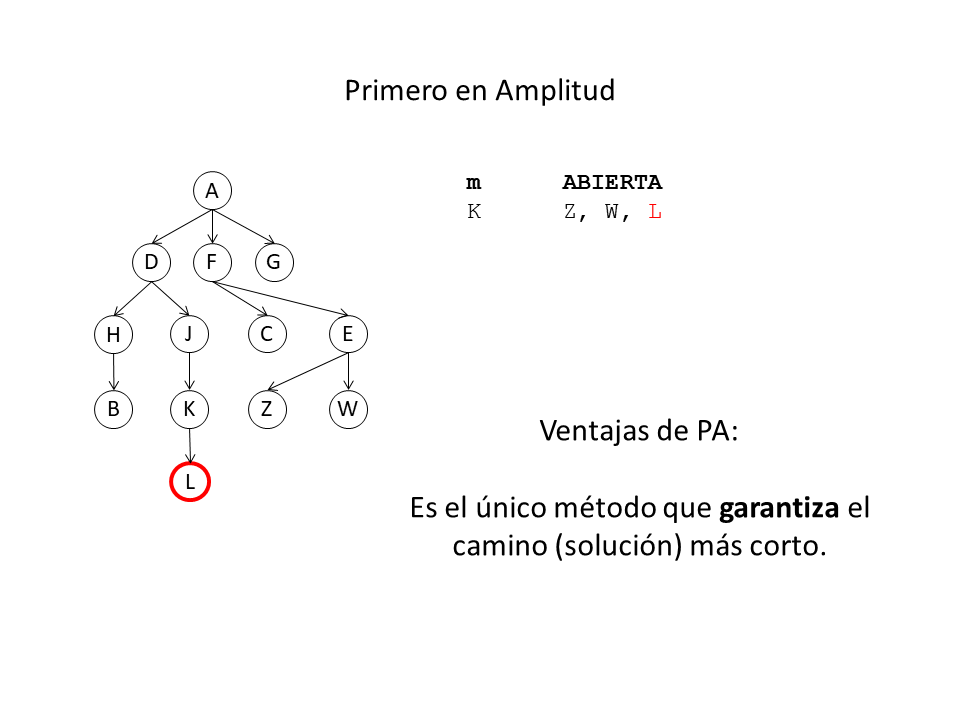

<center>

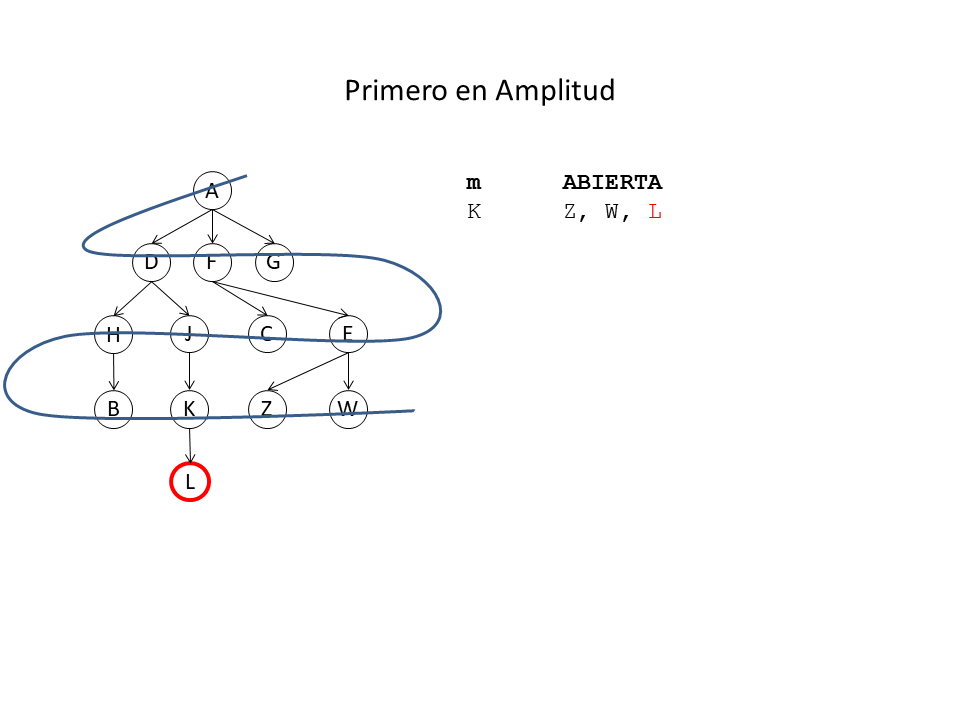

### En código...

In [1]:
import numpy as np
import copy

In [ ]:
# Estado final (GOAL) y varias versiones de estado inicial

GOAL = ((' ', '1', '2'), ('3', '4', '5'), ('6', '7', '8'))
estado_inicial = (('1', '2', '5'), ('3', '7', '4'), (' ', '6', '8'))
# estado_inicial = (('1', '2', '5'), ('3', '7', ' '), ('4', '6', '8'))
# estado_inicial = (('2', '5', '7'), (' ', '1', '3'), ('4', '6', '8'))
# estado_inicial = (('7', '2', '4'), ('5', ' ', '6'), ('8', '3', '1'))

In [ ]:
# Definición del problema

class Puzzle8():
    def actions(self, state):
        st = np.array(state)
        actionlist = []
        coord = np.where(st == ' ')
        i = coord[0][0]
        j = coord[1][0]
        if i > 0:
          actionlist = actionlist + ['m_aba']
        if i < 2:
          actionlist = actionlist + ['m_arr']
        if j > 0:
          actionlist = actionlist + ['m_der']
        if j < 2:
          actionlist = actionlist + ['m_izq']
        return actionlist

    def result(self, state, action):
        res = np.array(state)
        coord = np.where(res == ' ')
        i = coord[0][0]
        j = coord[1][0]
        if action == 'm_aba':
            res[i, j] = str(res[i-1, j])
            res[i-1, j] = ' '
        elif action == 'm_arr':
            res[i, j] = str(res[i+1, j])
            res[i+1, j] = ' '
        elif action == 'm_der':
            res[i, j] = str(res[i, j-1])
            res[i, j-1] = ' '
        elif action == 'm_izq':
            res[i, j] = str(res[i, j+1])
            res[i, j+1] = ' '
        return tuple(map(tuple, np.ndarray.tolist(res)))

    def is_goal(self, state):
        return state == GOAL


In [ ]:
# Primero en Amplitud

p = Puzzle8()
ABIERTA = [(estado_inicial, 0)]
encontrado = False
c = 0
while not encontrado and len(ABIERTA) > 0:
  m, nivel = ABIERTA.pop(0)
  c = c + 1
  if p.is_goal(m):
    encontrado = True
  else:
    for action in p.actions(m):
      ABIERTA.append((p.result(m, action), nivel + 1))

if encontrado:
  print('Objetivo encontrado!!')
  print(m)
  print('Nivel: %d' % nivel)
else:
  print('Objetivo NO encontrado')
print("Estados explorados: %d" %c)
print("Estados pendientes de explorar: %d" %len(ABIERTA))

Objetivo encontrado!!
((' ', '1', '2'), ('3', '4', '5'), ('6', '7', '8'))
Nivel: 6
Estados explorados: 470
Estados pendientes de explorar: 831


## Primero en profundidad

### Ejemplo

<center>

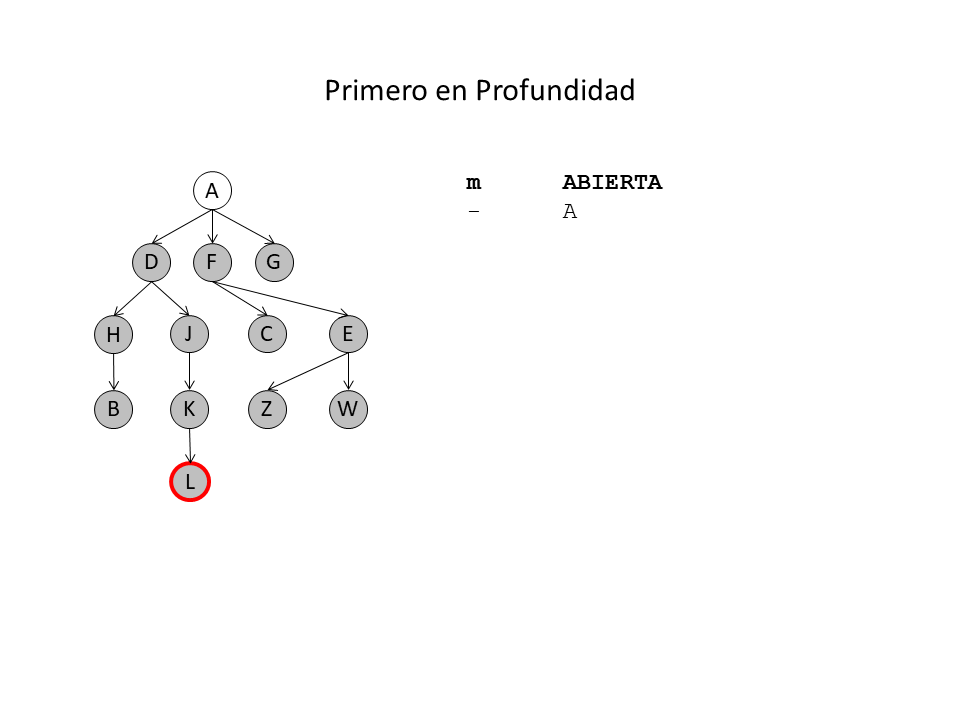

<center>

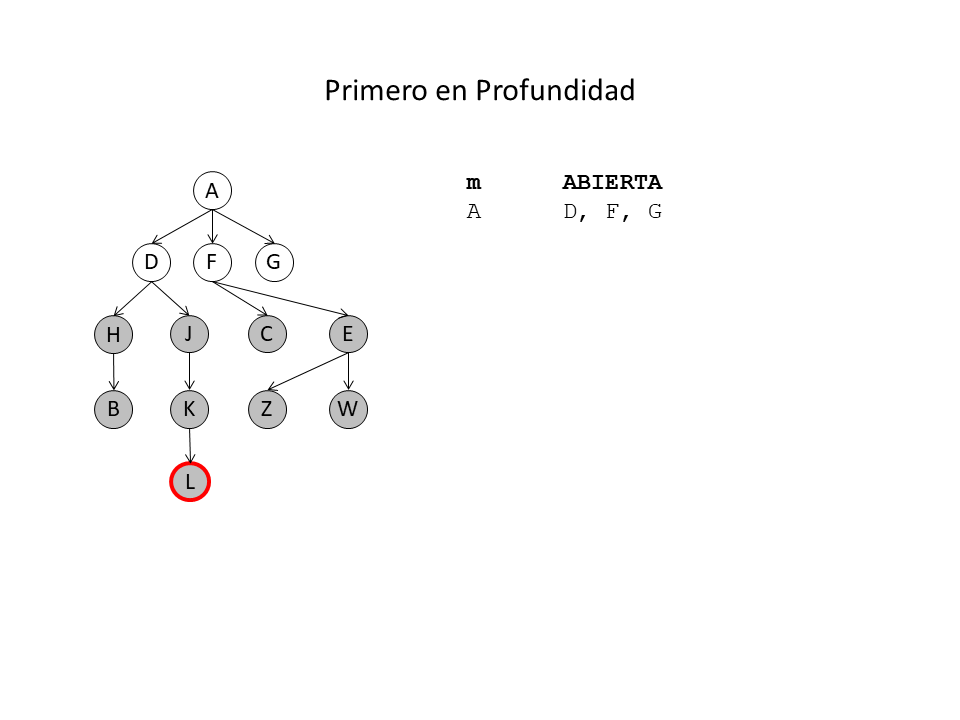

<center>

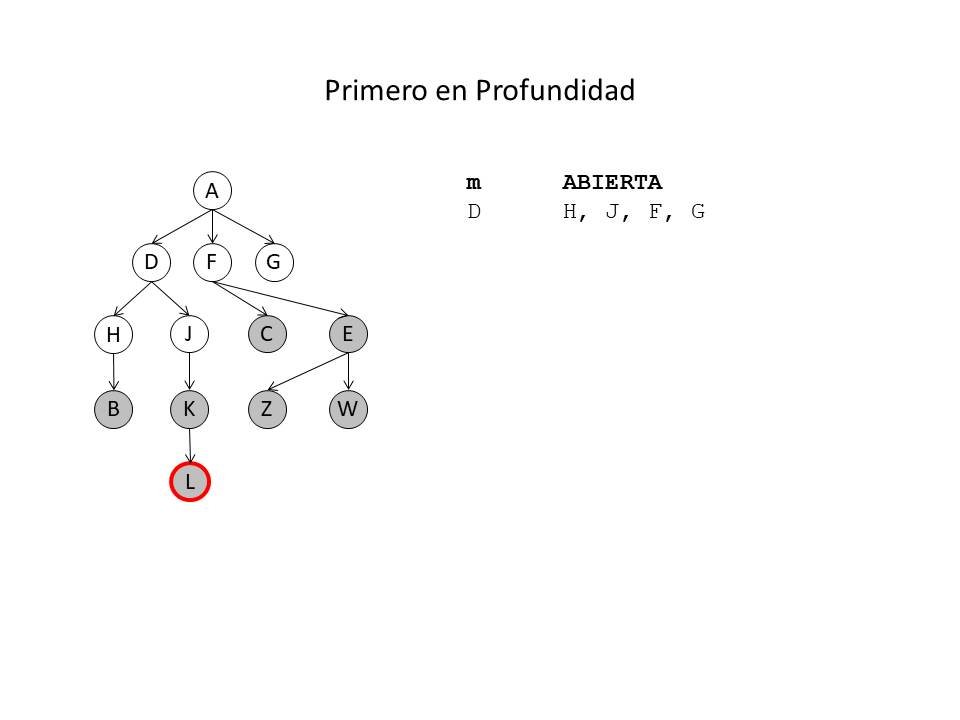

<center>

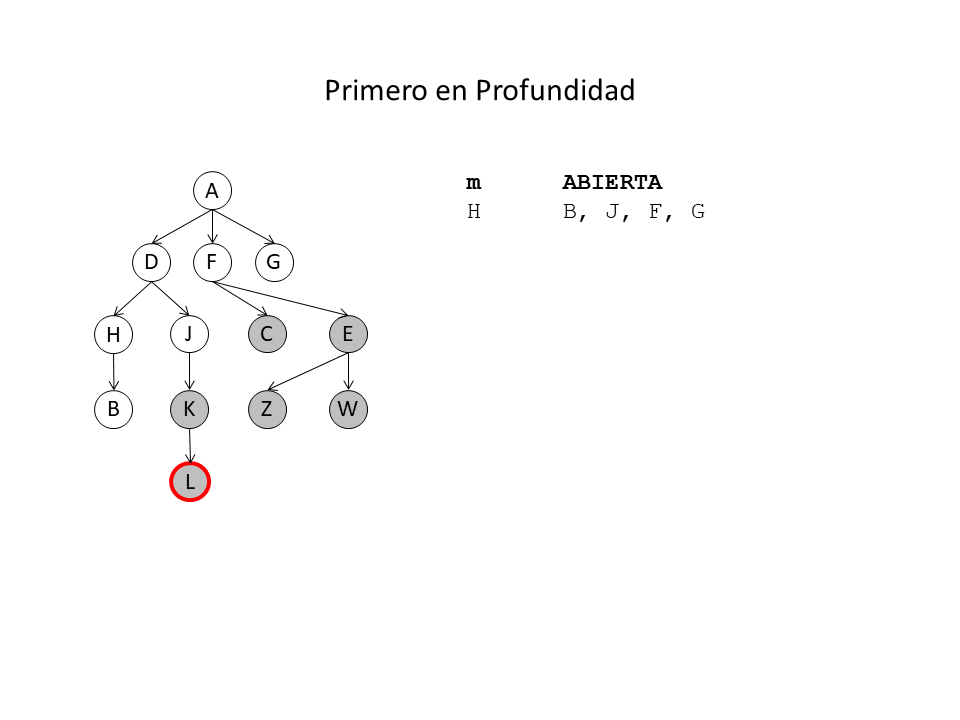

<center>

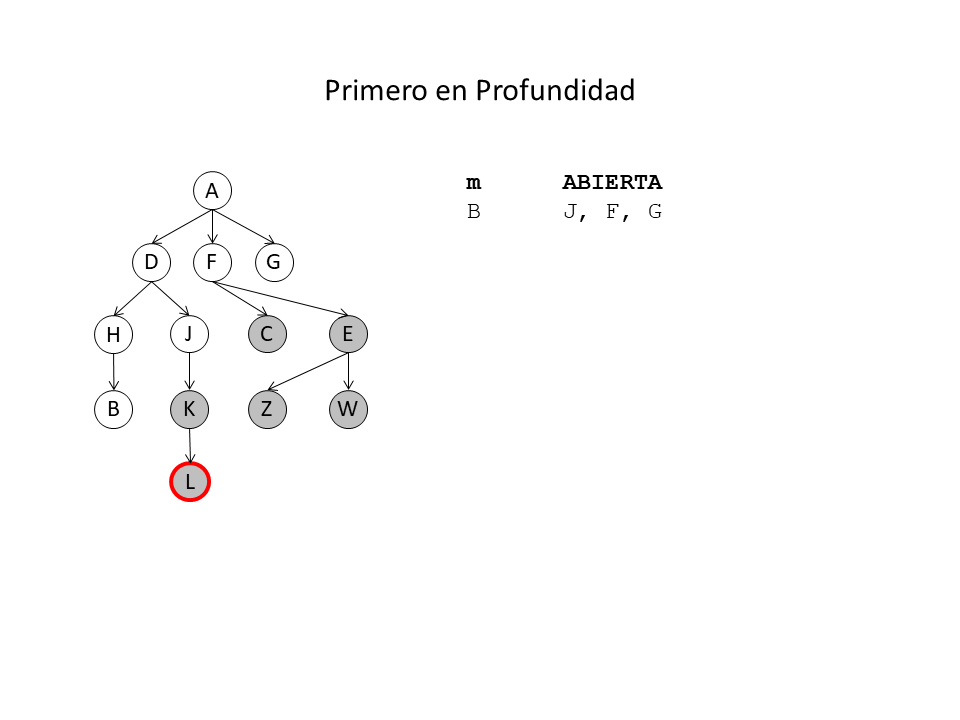

<center>

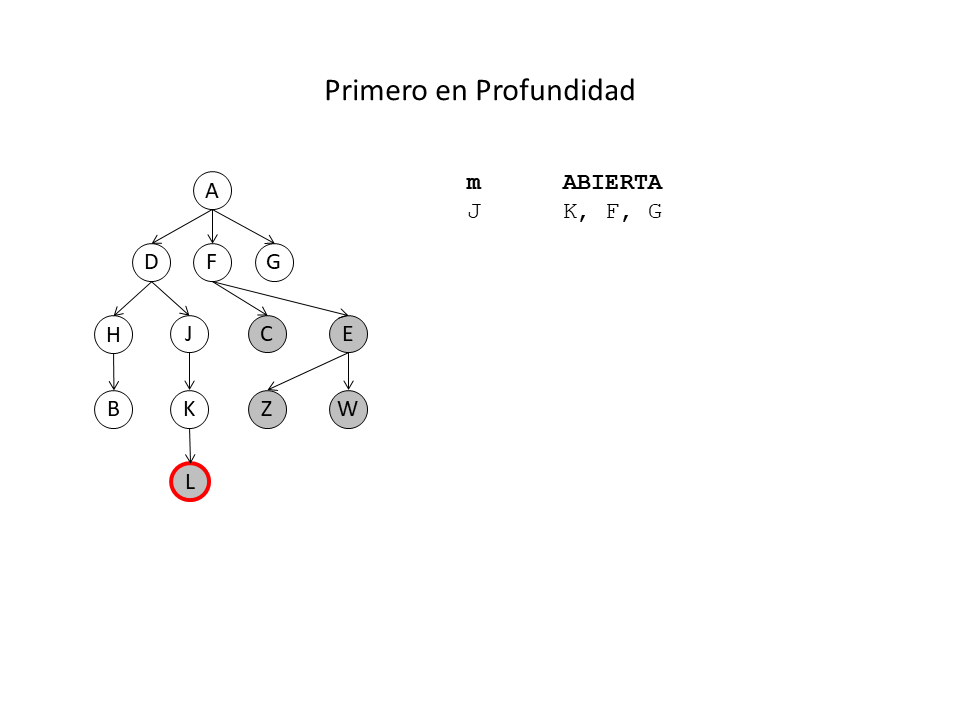

<center>

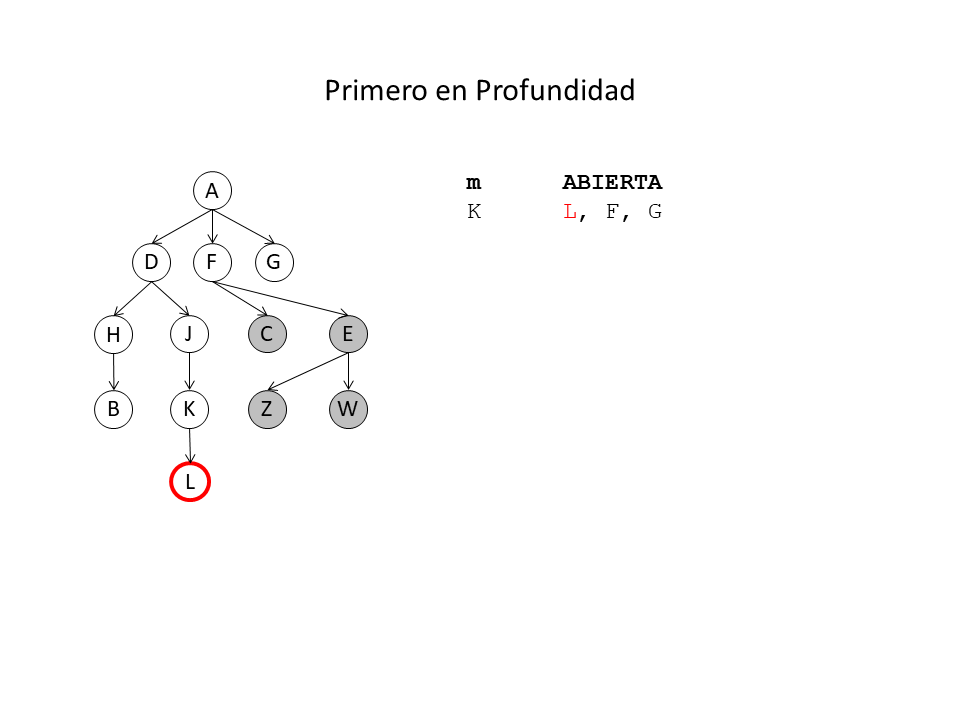

<center>

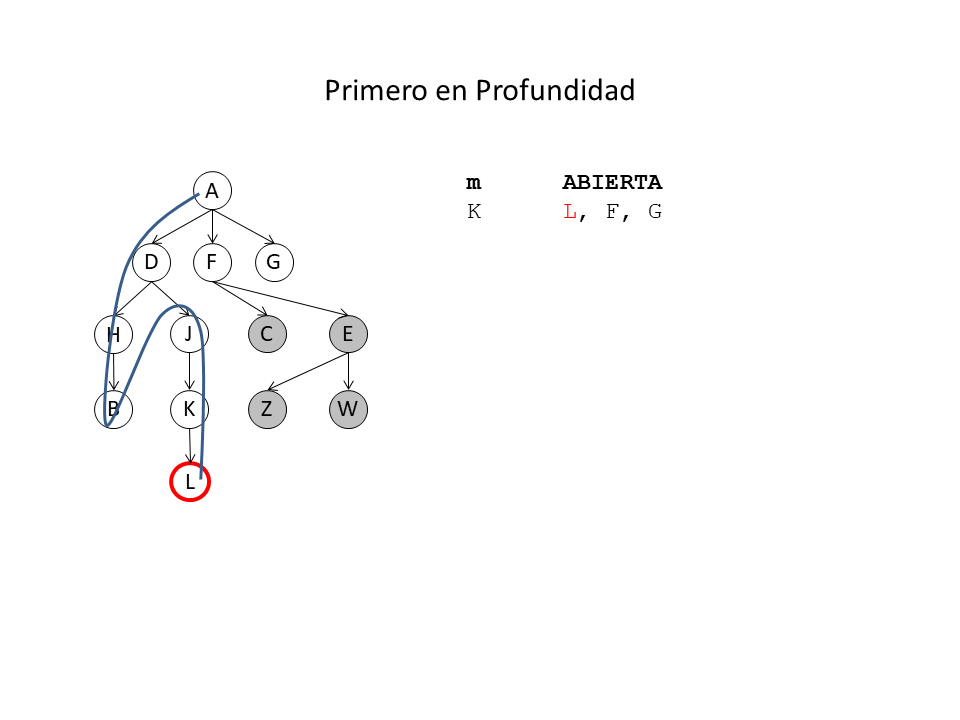

### En código...

In [ ]:
# Primero en profundidad

nivel_max = 100
p = Puzzle8()
ABIERTA = [(estado_inicial, 0)]
encontrado = False
c = 0
while not encontrado and len(ABIERTA) > 0:
  m, nivel = ABIERTA.pop(0)
  c = c + 1
  if p.is_goal(m):
    encontrado = True
  else:
    if nivel_max > nivel:
      for action in p.actions(m):
        ABIERTA.insert(0, (p.result(m, action), nivel + 1))

if encontrado:
  print('Objetivo encontrado!!')
  print(m)
  print('Nivel: %d' % nivel)
else:
  print('Objetivo NO encontrado')
print("Estados explorados: %d" %c)
print("Estados pendientes de explorar: %d" %len(ABIERTA))

Objetivo encontrado!!
((' ', '1', '2'), ('3', '4', '5'), ('6', '7', '8'))
Nivel: 100
Estados explorados: 274
Estados pendientes de explorar: 147


## Métodos informados (heurísticos)

El conocimiento del dominio del problema puede ayudar a dirigir el proceso de búsqueda de manera que sean exploradas en primer lugar aquellas trayectorias más prometedoras.

## Heurística

* Una de las definiciones de la RAE: “En algunas ciencias, manera de buscar la solución de un problema mediante métodos no rigurosos, como por tanteo, reglas empíricas, etc.”
* Para los métodos de búsqueda, es una técnica que aumenta la eficiencia del proceso, posiblemente sacrificando demandas de completitud.
* Es conocimiento (muchas veces intuitivo) que puede guiar el proceso de búsqueda.
* Las heurísticas no garantizan la solución óptima, pero generalmente mejoran la calidad del proceso.


## Función heurística

* El conocimiento heurístico generalmente se incorpora al proceso de búsqueda a través de una **función heurística**.
* La función heurística determina un grado de “bondad” para cada estado evaluado.


## Ejemplo de función heurística

<center>

**8-puzzle**

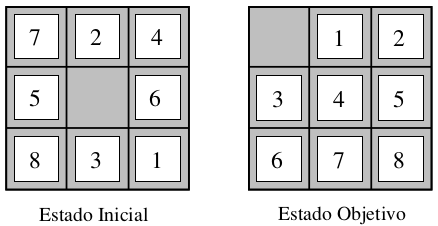

### ...

* Suma de las fichas mal ubicadas.
* Suma de las distancias (de Manhattan) entre la posición actual de cada ficha y su posición objetivo.

## Métodos informados

* Escalada simple
* Escalada por la máxima pendiente
* Enfriamiento simulado
* Primero el mejor
* A*

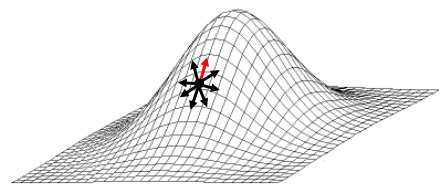


## Método *Primero el Mejor* (PEM)

* Utiliza una lista (ABIERTA) para guardar los estados a recorrer.
* La lista ABIERTA se ordena según el valor de la heurística (primero el mejor)
* Se utiliza otra lista (CERRADA) para guardar los estados recorridos.
* La heurística $h’$ es la distancia estimada al estado objetivo.


## Ejemplo de PEM

Detalles en el ejemplo:

* No se permite la creación de estados repetidos, por lo tanto, la estructura que representa el espacio de estados ya no es un árbol sino un grafo (Es lo más frecuente).

* Se controla el estado objetivo inmediatamente después de crear un nuevo estado (En este caso ahorra recursos, pero no siempre es la mejor elección).

### Ejemplo

<center>

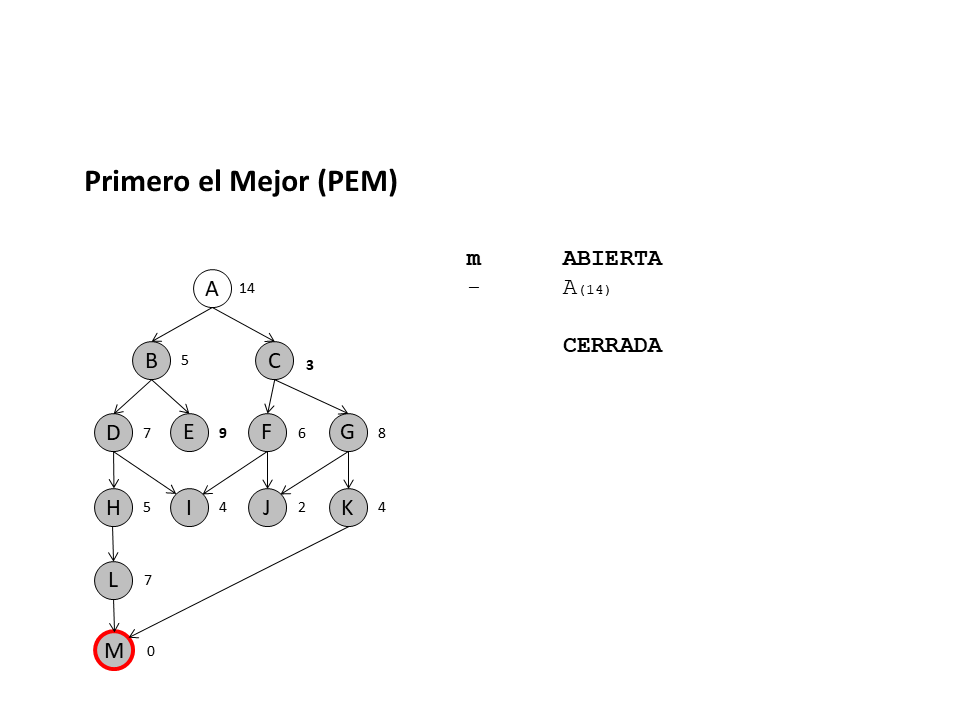

<center>

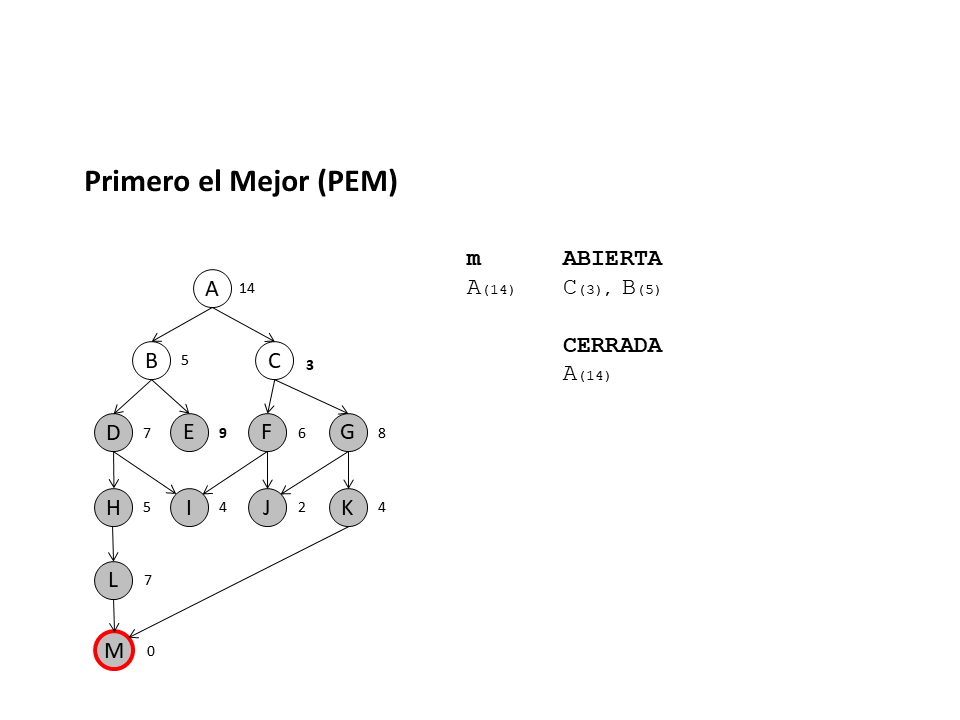

<center>

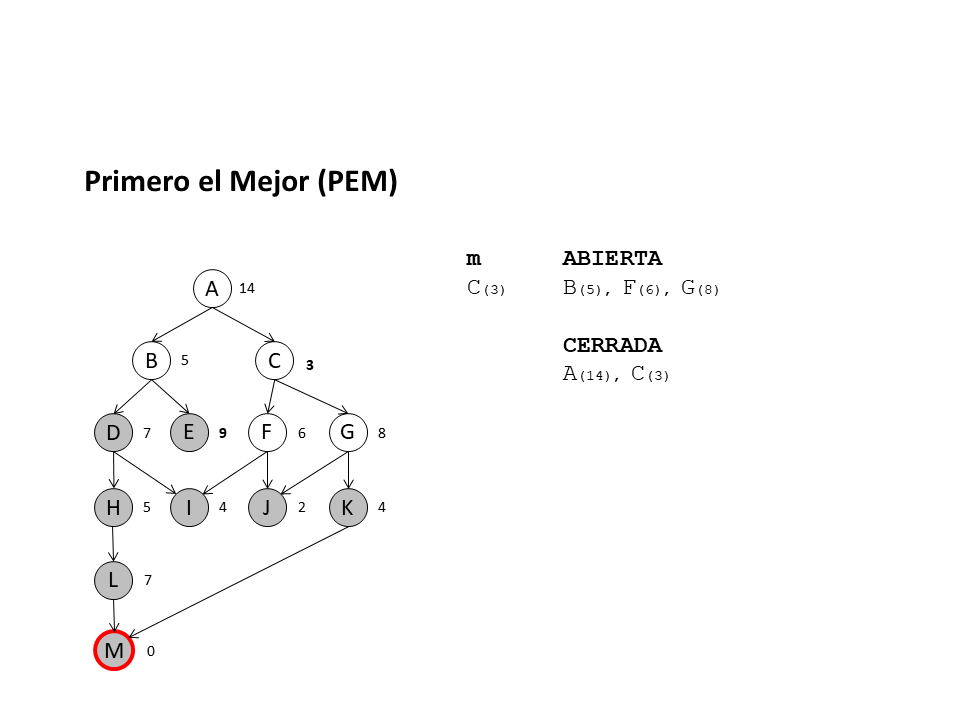

<center>

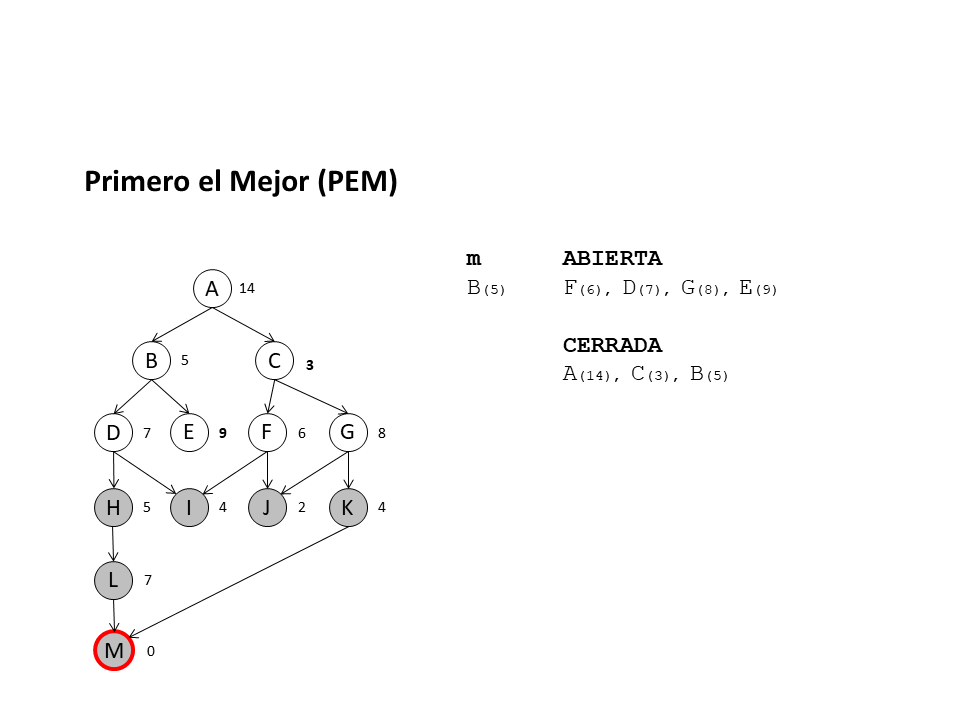

<center>

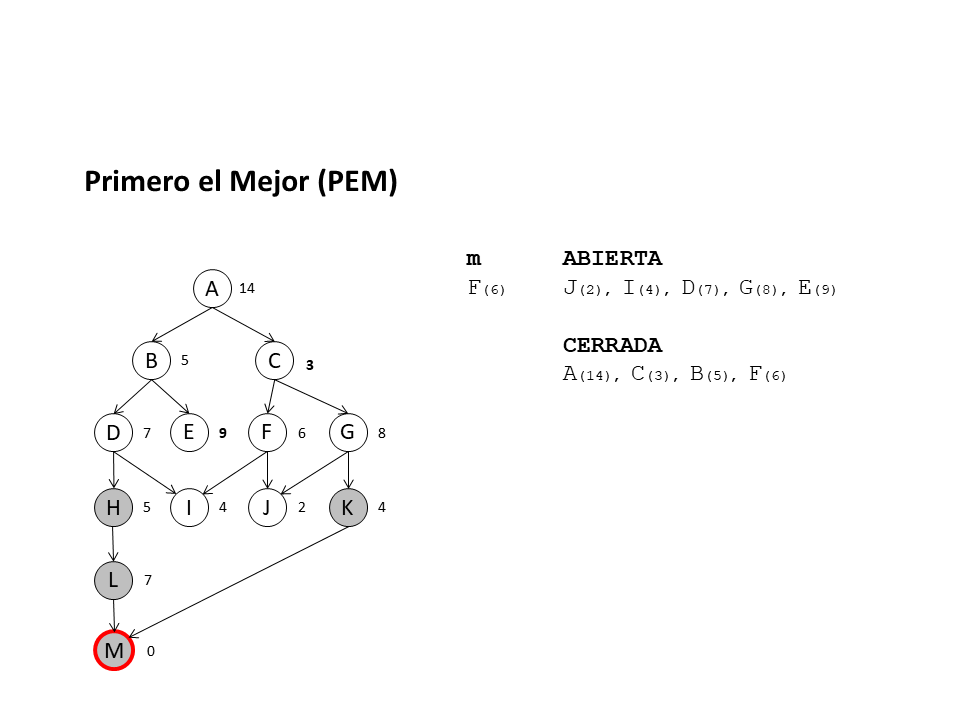

<center>

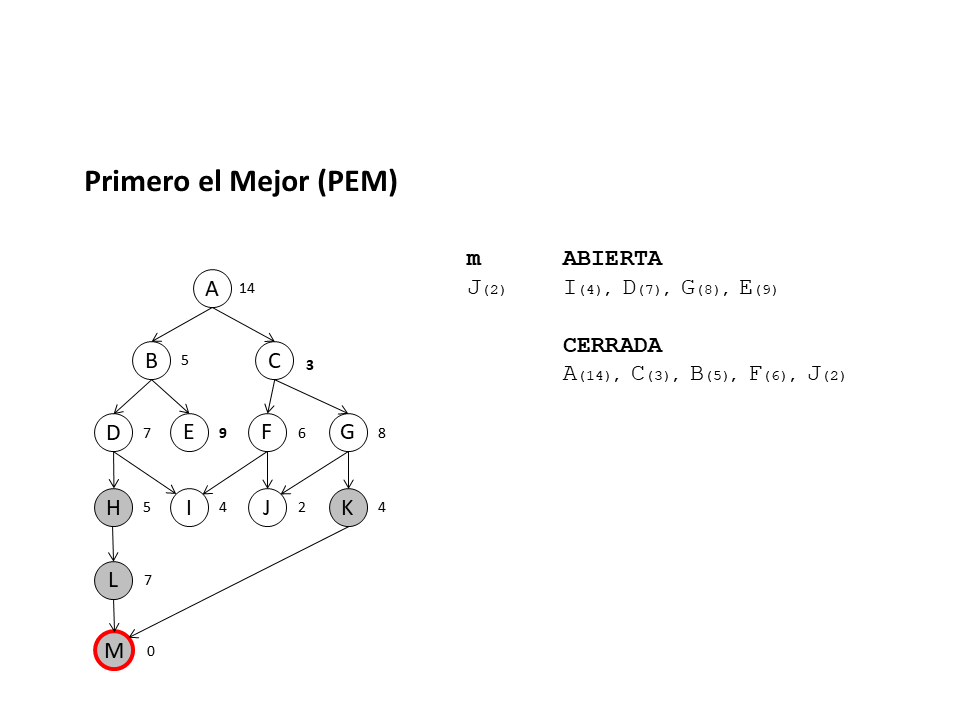

<center>

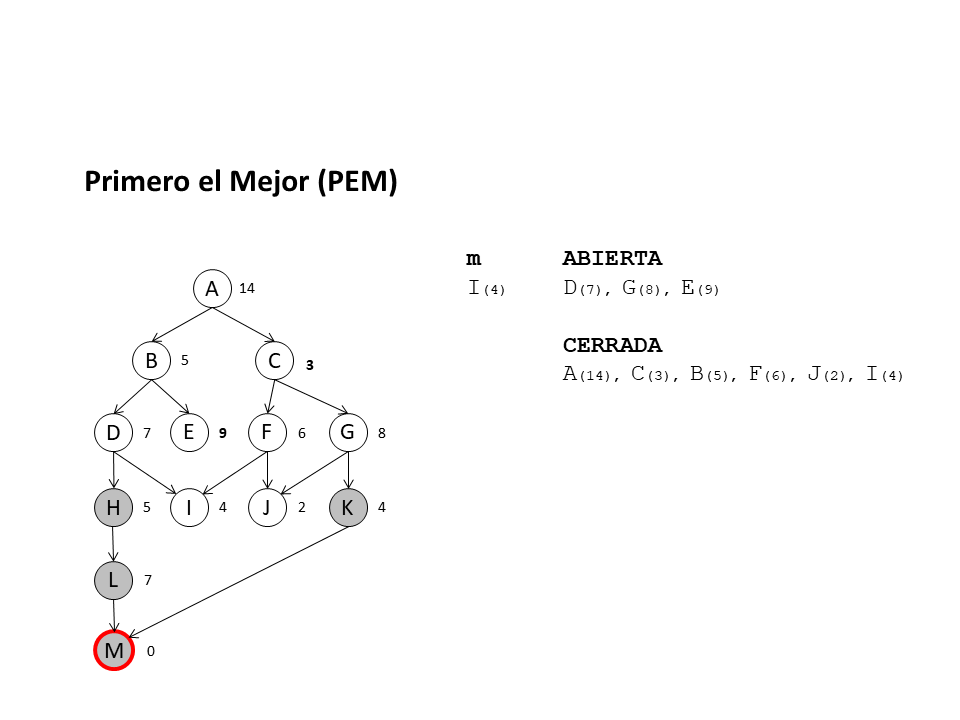

<center>

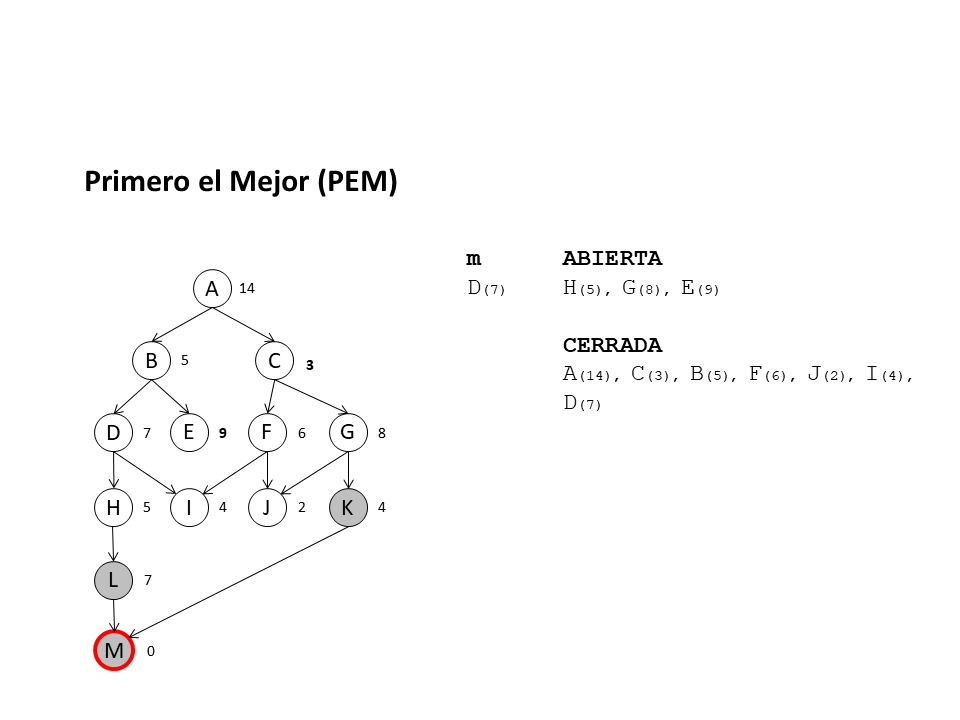

<center>

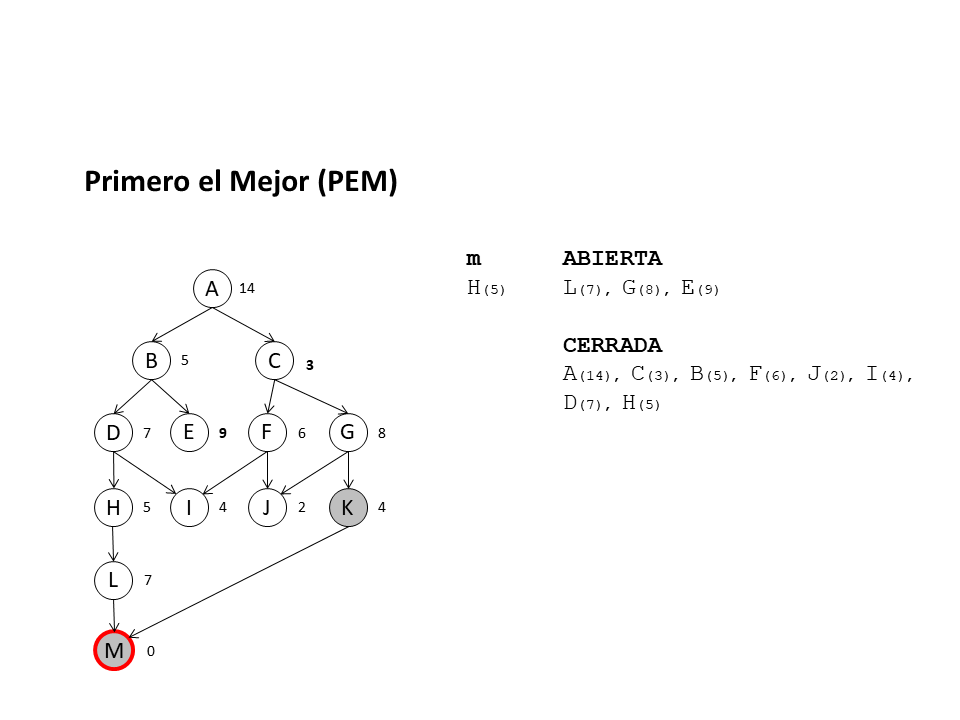

<center>

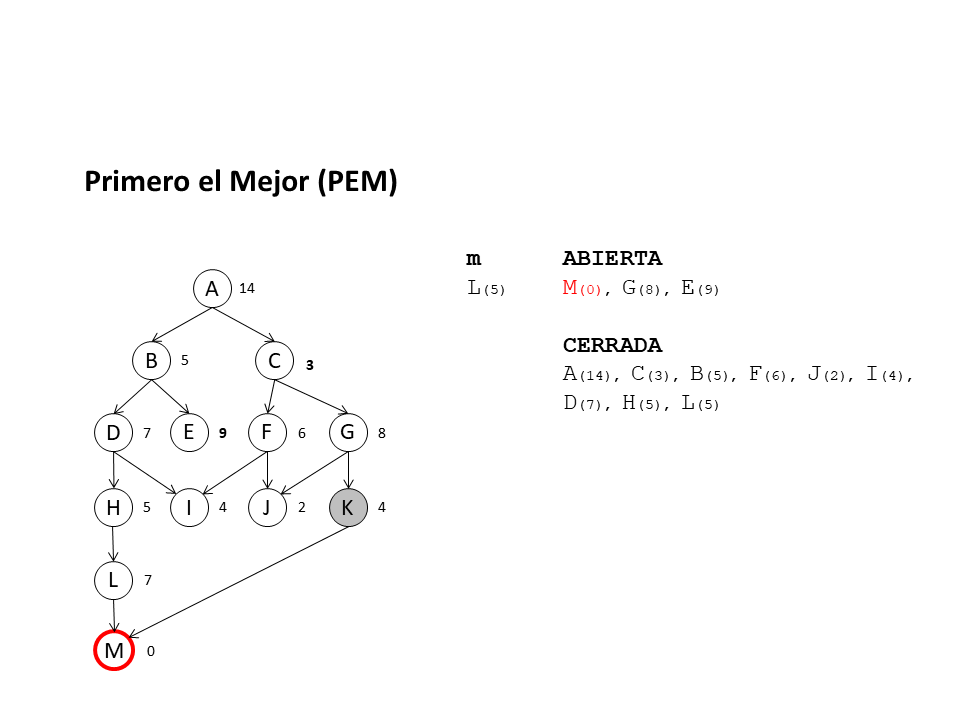

<center>

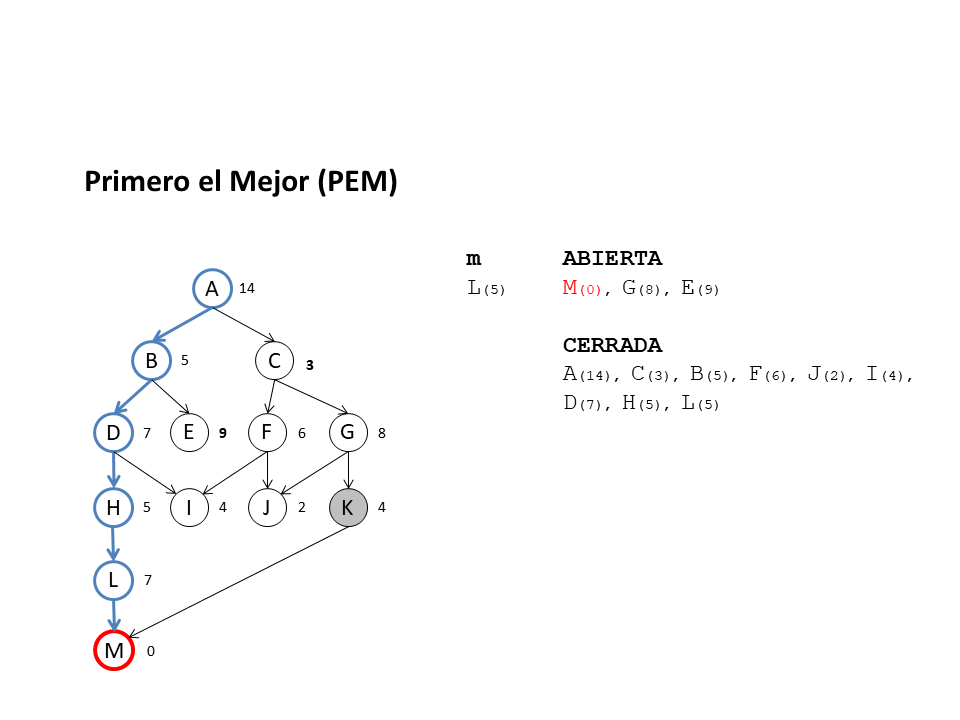

### En código...

In [ ]:
class Puzzle8():
    def actions(self, state):
        st = np.array(state)
        actionlist = []
        coord = np.where(st == ' ')
        i = coord[0][0]
        j = coord[1][0]
        if i > 0:
          actionlist = actionlist + ['m_aba']
        if i < 2:
          actionlist = actionlist + ['m_arr']
        if j > 0:
          actionlist = actionlist + ['m_der']
        if j < 2:
          actionlist = actionlist + ['m_izq']
        return actionlist

    def result(self, state, action):
        res = np.array(state)
        coord = np.where(res == ' ')
        i = coord[0][0]
        j = coord[1][0]
        if action == 'm_aba':
            res[i, j] = res[i-1, j]
            res[i-1, j] = ' '
        elif action == 'm_arr':
            res[i, j] = res[i+1, j]
            res[i+1, j] = ' '
        elif action == 'm_der':
            res[i, j] = res[i, j-1]
            res[i, j-1] = ' '
        elif action == 'm_izq':
            res[i, j] = res[i, j+1]
            res[i, j+1] = ' '
        return tuple(map(tuple, np.ndarray.tolist(res)))

    def is_goal(self, state):
        return state == GOAL

    def heuristic(self, state):
    # Constante
      # return 1

    # Fichas mal ubicadas
      # return 9 - (np.array(state) == np.array(GOAL)).sum()

    # Distancia de Manhattan
      h = 0
      gl = np.array(GOAL)
      for i in range(3):
        for j in range(3):
          igl, jgl = np.where(gl == state[i][j])
          h = h + abs(igl[0] - i) + abs(jgl[0] - j)
      return h

In [ ]:
# Primero el Mejor

p = Puzzle8()
ABIERTA = [(-1, estado_inicial, 0)]
encontrado = False
c = 0
while not encontrado and len(ABIERTA) > 0:
  heu, m, nivel = ABIERTA.pop(0)
  c = c + 1
  if p.is_goal(m):
    encontrado = True
  else:
    for action in p.actions(m):
      hijo = p.result(m, action)
      ABIERTA.append((p.heuristic(hijo), hijo, nivel + 1))
    ABIERTA = sorted(ABIERTA, key=lambda tup: tup[0])

if encontrado:
  print('Objetivo encontrado!!')
  print(m)
  print('Nivel: %d' % nivel)
else:
  print('Objetivo NO encontrado')
print("Estados explorados: %d" %c)
print("Estados pendientes de explorar: %d" %len(ABIERTA))


Objetivo encontrado!!
((' ', '1', '2'), ('3', '4', '5'), ('6', '7', '8'))
Nivel: 6
Estados explorados: 11
Estados pendientes de explorar: 18


## Método A*

* Utiliza una heurística $f’ = h’ + g$, donde $g$ es la cantidad de estados recorridos hasta llegar al estado actual.
$g$ es una penalización a los caminos largos.
* La ventaja de A* es que encuentra caminos más cortos.
* Si la heurística es optimista (admisible en el libro) y consistente (desigualdad triangular), no se permiten estados repetidos, se controla la condición de estado objetivo cuando se saca el estado de la lista ABIERTA y se tiene en cuenta un *detalle* que veremos en el ejemplo, garantiza la solución óptima.



### Ejemplo

<center>

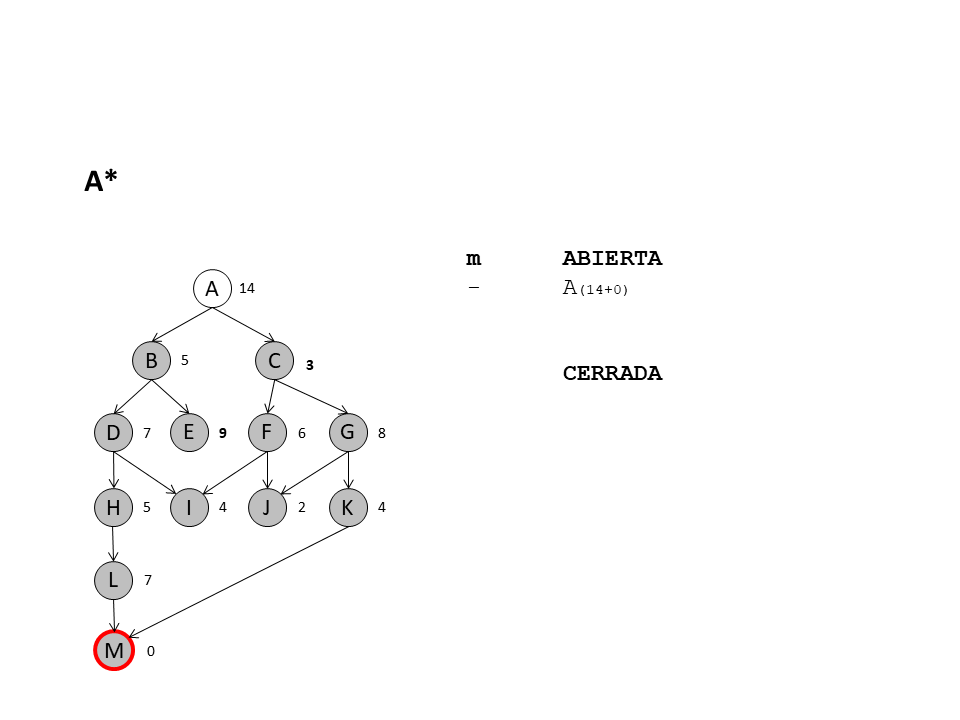

<center>

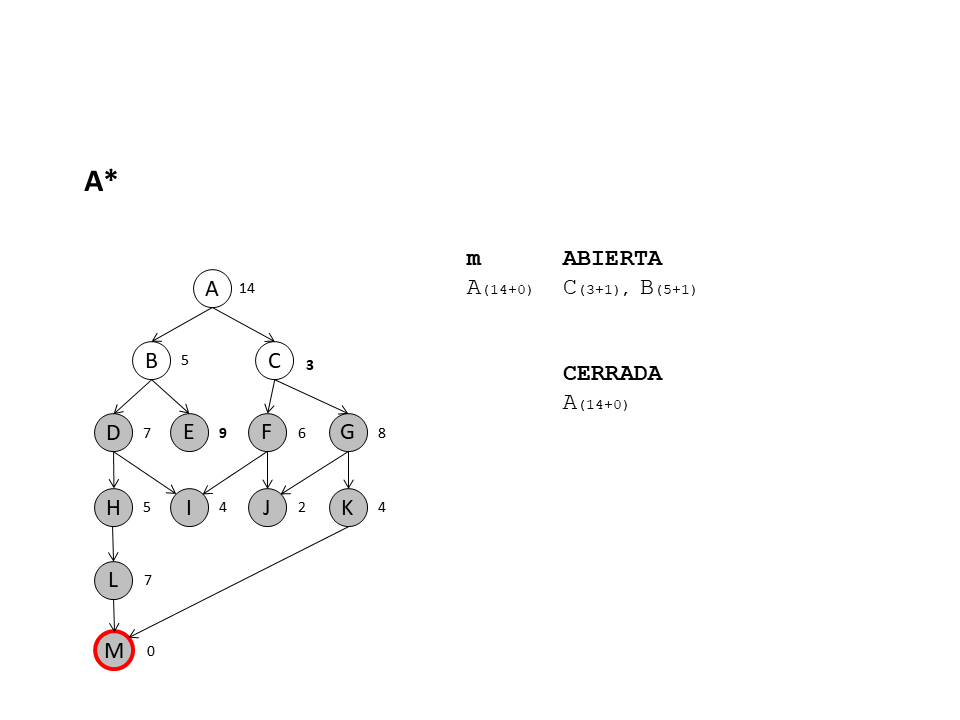

<center>

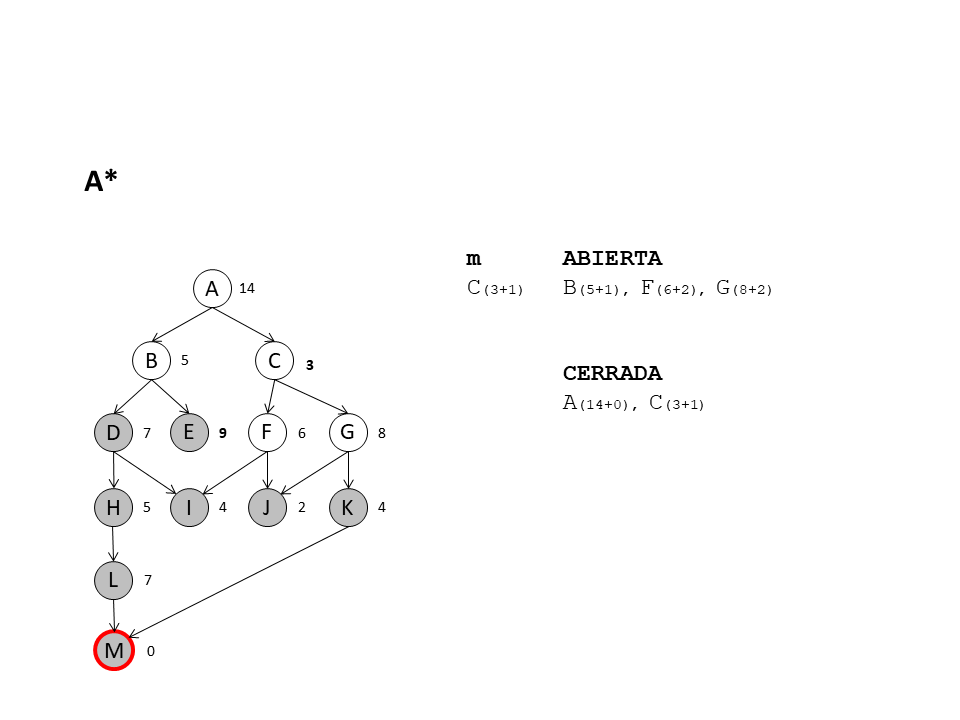

<center>

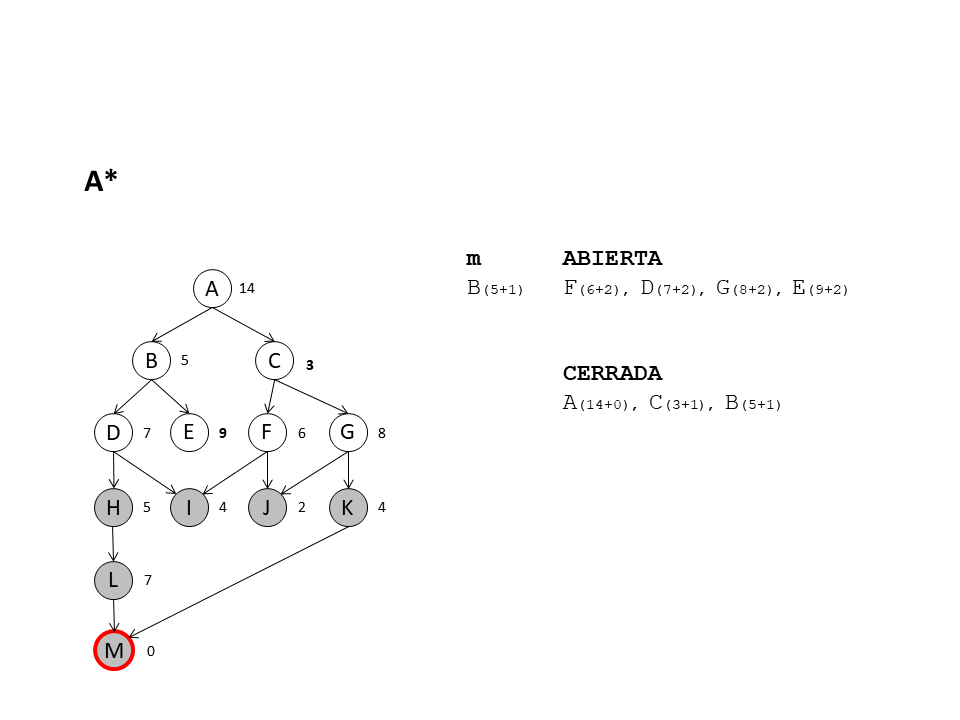

<center>

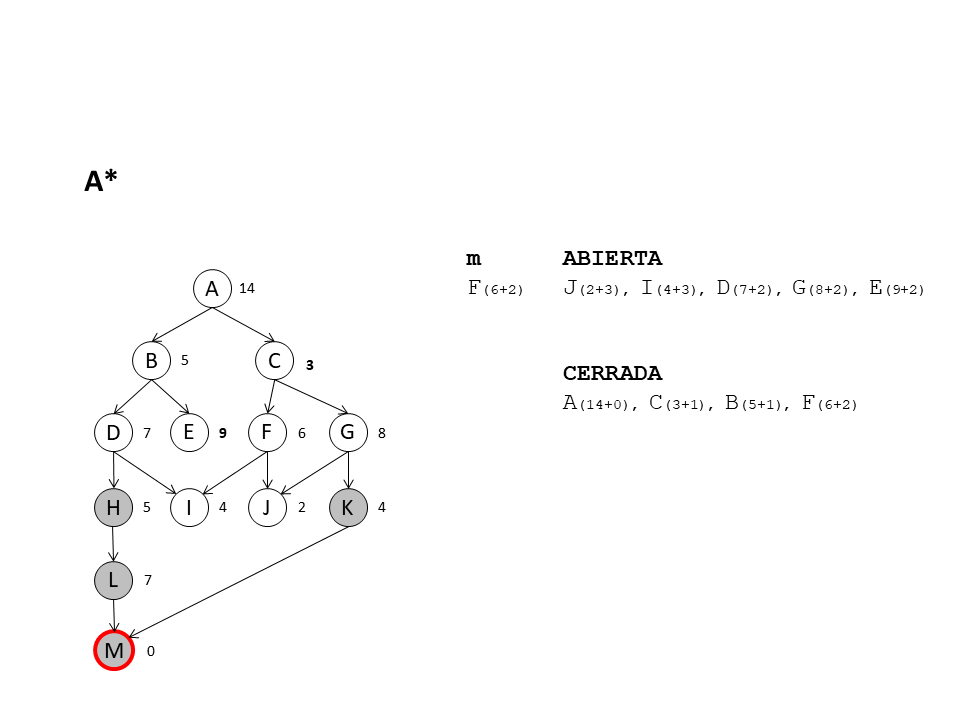

<center>

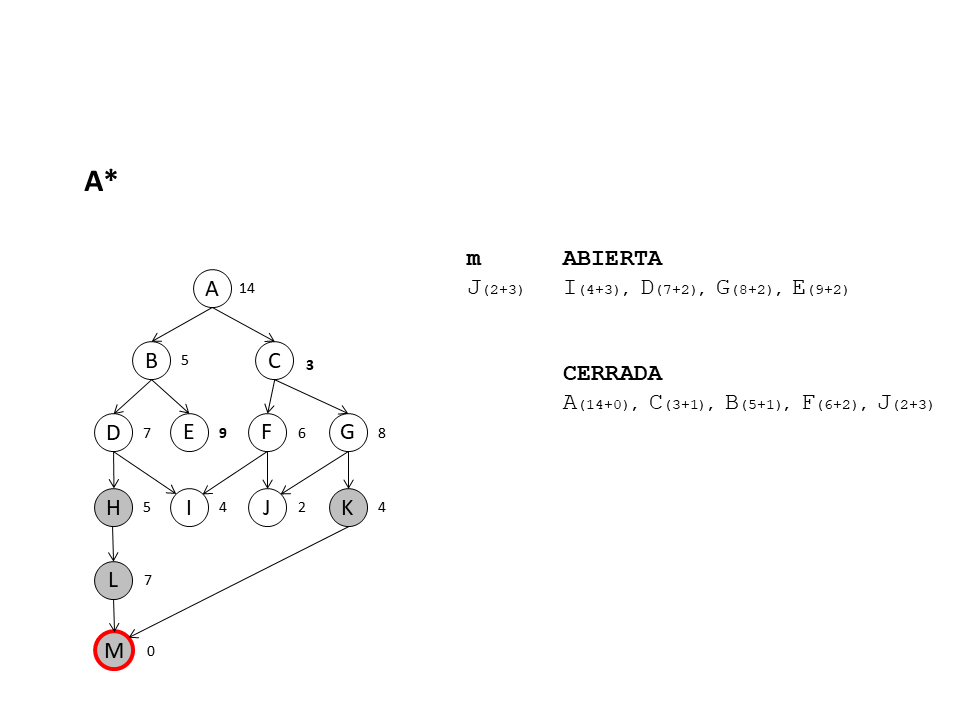

<center>

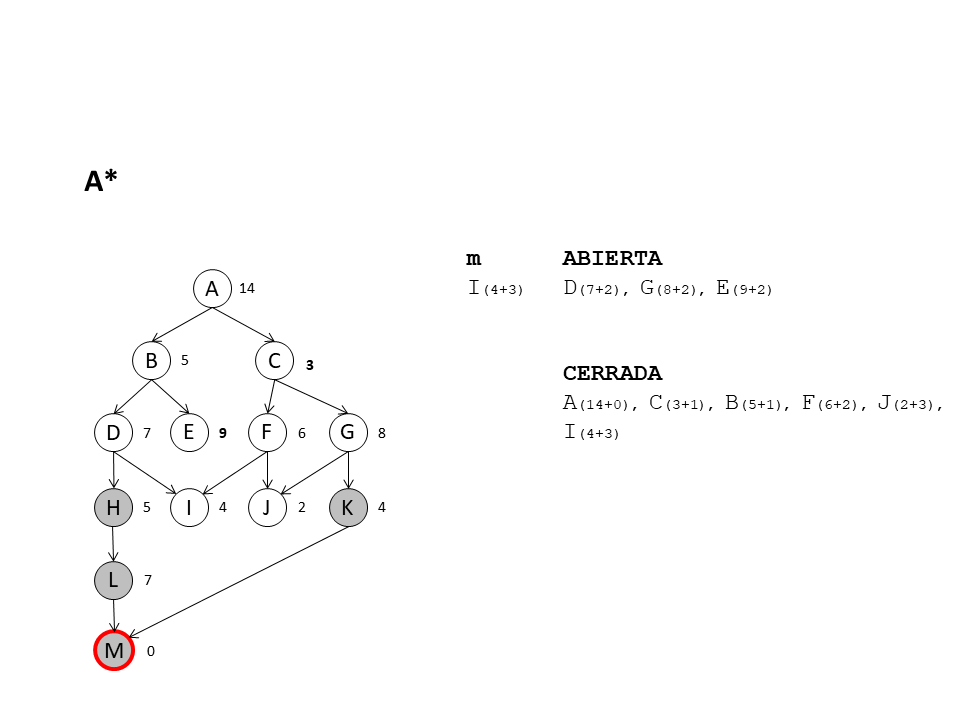

<center>

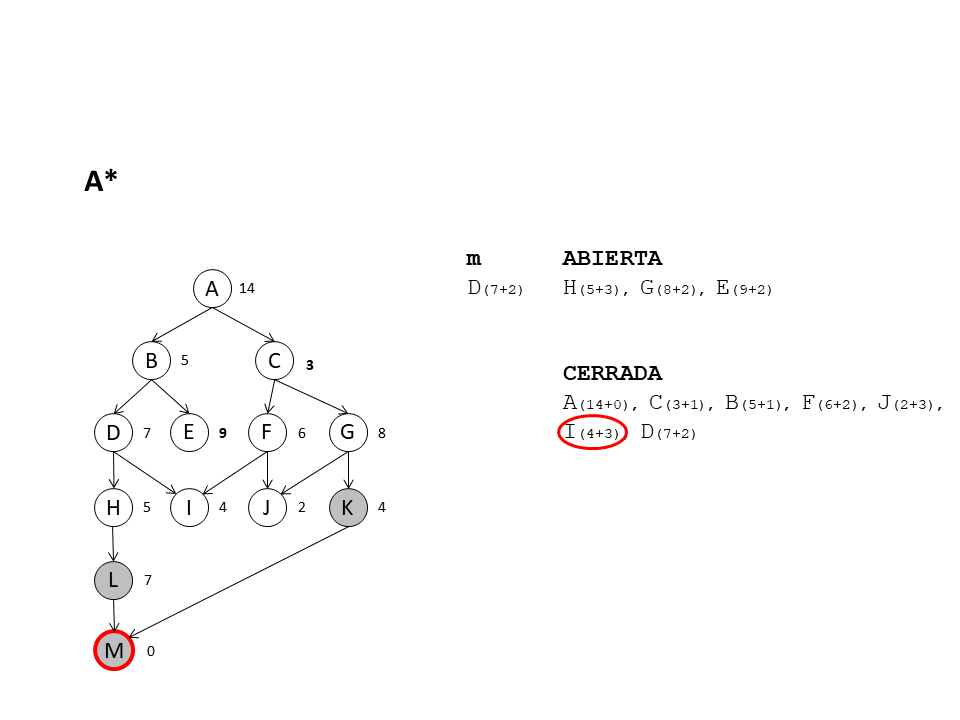

<center>

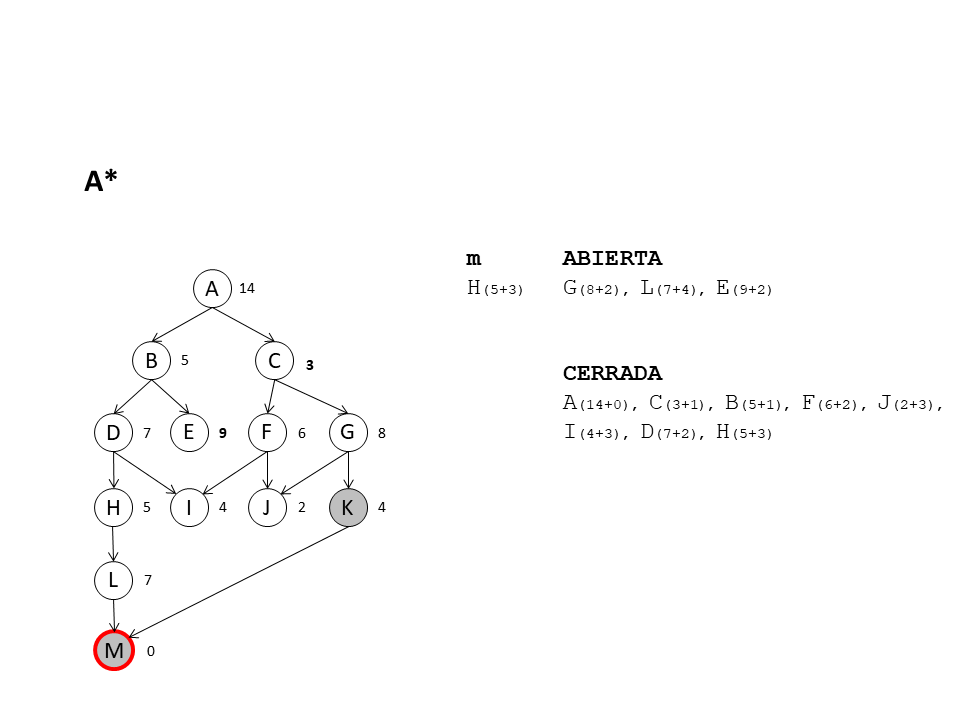

<center>

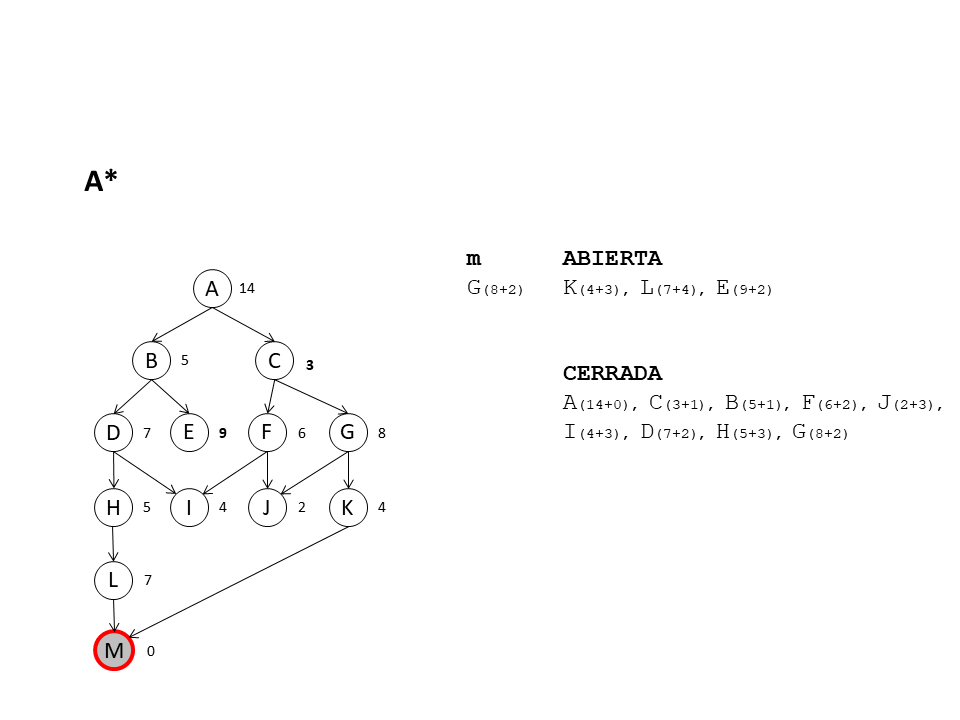

<center>

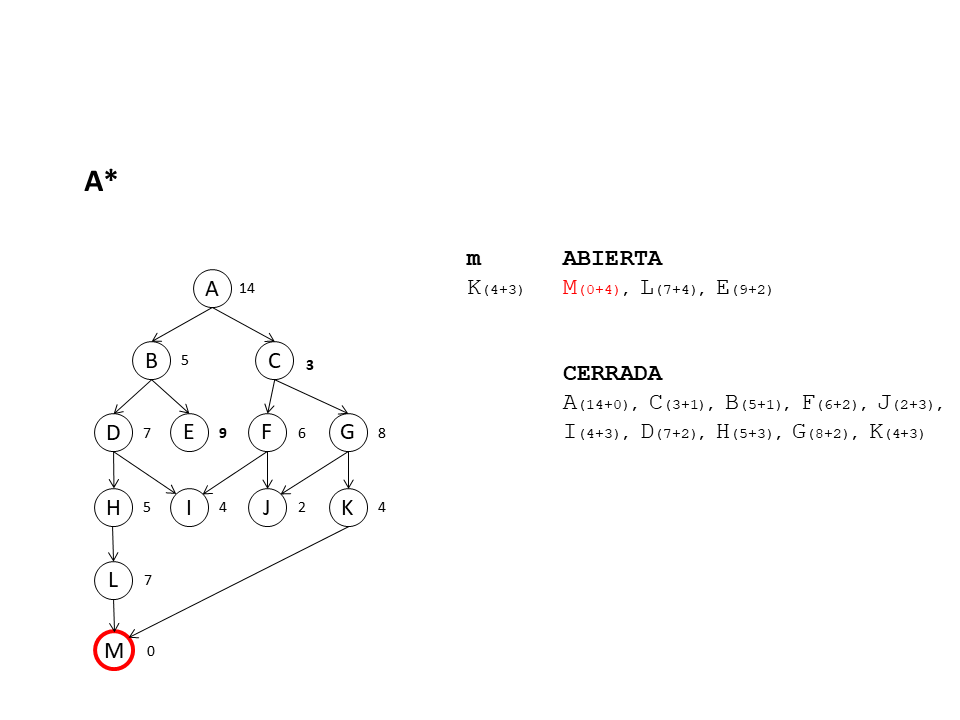

<center>

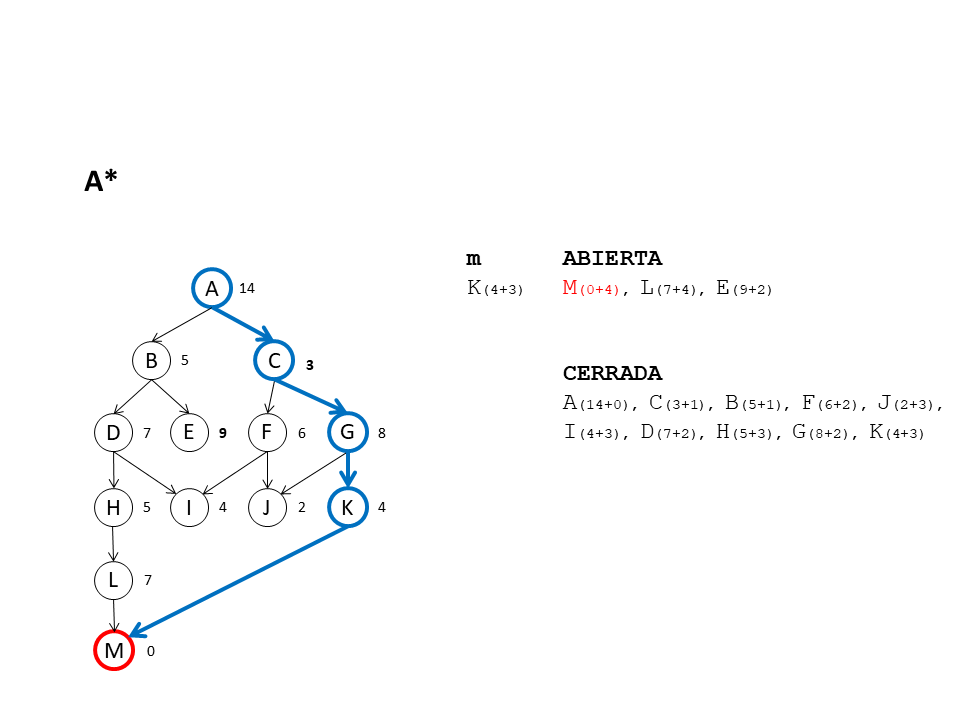

### En código...

In [ ]:
# A*

p = Puzzle8()
ABIERTA = [(-1, estado_inicial, 0)]
encontrado = False
c = 0
while not encontrado and len(ABIERTA) > 0:
  heu, m, nivel = ABIERTA.pop(0)
  c = c + 1 # Función de costo es constante = 1
  if p.is_goal(m):
    encontrado = True
  else:
    for action in p.actions(m):
      hijo = p.result(m, action)
      ABIERTA.append((p.heuristic(hijo) + nivel + 1, hijo, nivel + 1))
    ABIERTA = sorted(ABIERTA, key=lambda tup: tup[0])

if encontrado:
  print('Objetivo encontrado!!')
  print(m)
  print("Nivel: %d" % nivel)
else:
  print('Objetivo NO encontrado')
print("Estados explorados: %d" %c)
print("Estados pendientes de explorar: %d" %len(ABIERTA))

Objetivo encontrado!!
((' ', '1', '2'), ('3', '4', '5'), ('6', '7', '8'))
Nivel: 6
Estados explorados: 11
Estados pendientes de explorar: 18


## Con SimpleAI (librería)

https://github.com/simpleai-team/simpleai

In [ ]:
! pip install simpleai

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.4/94.4 kB 2.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for simpleai: filename=simpleai-0.8.3-py3-none-any.whl size=100982 sha256=3ed3b73b538e24156ec739bb76e95d6493c7ae60e52714682c53c74ab507cd4f
  Stored in directory: /root/.cache/pip/wheels/04/84/76/e493a82b60c25f283e4d315ac3b9b9ff44470556da775c58ad
Successfully built simpleai


In [ ]:
from simpleai.search import SearchProblem, astar

class Puzzle8(SearchProblem):
    def actions(self, state):
        st = np.array(state)
        actionlist = []
        coord = np.where(st == ' ')
        i = coord[0][0]
        j = coord[1][0]
        if i > 0:
          actionlist = actionlist + ['m_aba']
        if i < 2:
          actionlist = actionlist + ['m_arr']
        if j > 0:
          actionlist = actionlist + ['m_der']
        if j < 2:
          actionlist = actionlist + ['m_izq']
        return actionlist


    def result(self, state, action):
        res = np.array(state)
        coord = np.where(res == ' ')
        i = coord[0][0]
        j = coord[1][0]
        if action == 'm_aba':
            res[i, j] = res[i-1, j]
            res[i-1, j] = ' '
        elif action == 'm_arr':
            res[i, j] = res[i+1, j]
            res[i+1, j] = ' '
        elif action == 'm_der':
            res[i, j] = res[i, j-1]
            res[i, j-1] = ' '
        elif action == 'm_izq':
            res[i, j] = res[i, j+1]
            res[i, j+1] = ' '
        return tuple(map(tuple, res))

    def is_goal(self, state):
        return state == GOAL

    def heuristic(self, state):
    # Fichas mal ubicadas
      # return 9 - (np.array(state) == np.array(GOAL)).sum()
    # Distancia de Manhattan
      h = 0
      gl = np.array(GOAL)
      for i in range(3):
        for j in range(3):
          igl, jgl = np.where(gl == state[i][j])
          h = h + abs(igl[0] - i) + abs(jgl[0] - j)
      return h
    # Constante
    #   return 1

problem = Puzzle8(initial_state = estado_inicial)
result = astar(problem, graph_search=False)

print(result.state)
print(result.path())
print(len(result.path()))

((np.str_(' '), np.str_('1'), np.str_('2')), (np.str_('3'), np.str_('4'), np.str_('5')), (np.str_('6'), np.str_('7'), np.str_('8')))
[(None, (('1', '2', '5'), ('3', '7', '4'), (' ', '6', '8'))), ('m_izq', ((np.str_('1'), np.str_('2'), np.str_('5')), (np.str_('3'), np.str_('7'), np.str_('4')), (np.str_('6'), np.str_(' '), np.str_('8')))), ('m_aba', ((np.str_('1'), np.str_('2'), np.str_('5')), (np.str_('3'), np.str_(' '), np.str_('4')), (np.str_('6'), np.str_('7'), np.str_('8')))), ('m_izq', ((np.str_('1'), np.str_('2'), np.str_('5')), (np.str_('3'), np.str_('4'), np.str_(' ')), (np.str_('6'), np.str_('7'), np.str_('8')))), ('m_aba', ((np.str_('1'), np.str_('2'), np.str_(' ')), (np.str_('3'), np.str_('4'), np.str_('5')), (np.str_('6'), np.str_('7'), np.str_('8')))), ('m_der', ((np.str_('1'), np.str_(' '), np.str_('2')), (np.str_('3'), np.str_('4'), np.str_('5')), (np.str_('6'), np.str_('7'), np.str_('8')))), ('m_der', ((np.str_(' '), np.str_('1'), np.str_('2')), (np.str_('3'), np.str_('4

# Actividad

* Hacer una copia del notebook.
* Modificar los cuatro métodos de forma tal que no permitan estados repetidos (grafo).
* Probar con todos los estados iniciales.
* Agregar al final una o más celdas con los resultados y conclusiones. Para cada caso informar:
  * Si se encontró un estado objetivo.
  * Si el estado objetivo fue el óptimo.
  * Tiempo de ejecución.
  * Profundidad.
  * Cantidad de estados analizados.
  * Cantidad de estados pendientes de analizar (en ABIERTA).
  * Comparación con los datos del mismo estado inicial para la versión original (árbol).
* Compartir el notebook y pegar el link en la actividad de la UV



# Preguntas tipo parcial

* En los parciales aparecerán preguntas muy distintas a los ejercicios de la guía y a las explicaciones textuales del material.
* ¿Cómo responderlas bien? Asistiendo y participando en las clases, estudiando el material, resolviendo los ejercicios de la guía y razonando. El material está preparados para que, con la ayuda de las clases, quien lo use correctamente genere un modelo mental que le permita resolver cualquier problema.

**Ejemplo de preguntas**:
<center>

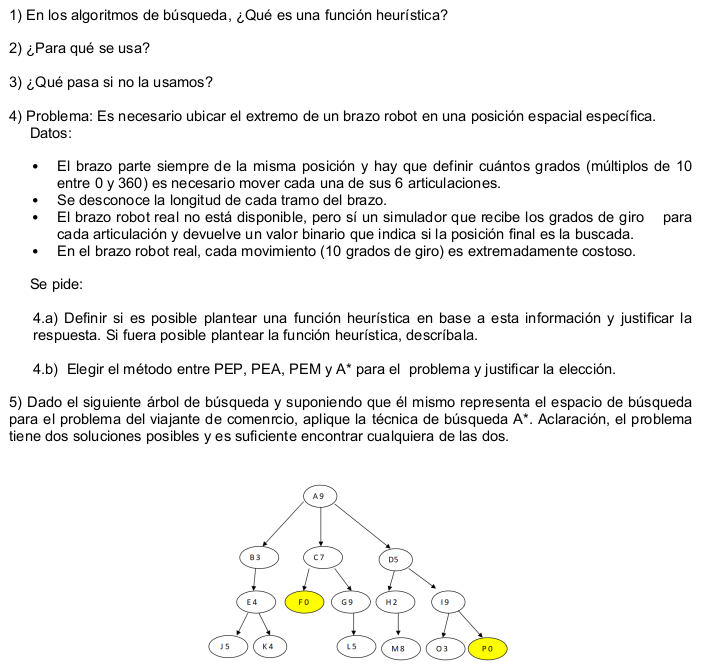